# 🎬 IMDb Sentiment Analysis — PIPELINE HOÀN CHỈNH TỪ DỮ LIỆU THÔ ĐẾN KẾT QUẢ CUỐI CÙNG

**Dự án:** Phân loại cảm xúc đánh giá phim IMDb bằng mô hình RNN (LSTM, GRU, BiLSTM, GloVe, Attention)  
**Phân công (Đại):** Toàn bộ các tasks **D1 → D8** theo [`docs/TASKS.md`](../docs/TASKS.md) §3, bao gồm cả bước tiền xử lý từ dữ liệu thô (raw data) theo chuẩn `docs/DATA.md`.  
**Mục tiêu:** Chạy thực nghiệm trên dữ liệu thật (Local GPU / Kaggle / Google Colab) để đưa ra toàn bộ số liệu, đồ thị và file bàn giao chính thức.

---

### 📑 Cấu trúc Pipeline 8 Bước:
1. **Khởi tạo Môi trường & Thiết bị:** Nhận diện GPU CUDA / CPU, cấu hình thư mục dự án.
2. **Dữ liệu Thô (Raw Data) & Tiền Xử Lý:** Tải/đọc dữ liệu thô `data/raw/`, làm sạch `<br />`, split theo phim, loại bỏ 123 review trùng với test, xuất `reviews.parquet`.
3. **Task D1 — Pipeline Dữ liệu:** Tokenizer bảo toàn phủ định (`not`, `n't`), Vocab chỉ từ train, Dataset & DataLoader với dynamic padding.
4. **Tasks D2 & D3 — Kiến trúc RNN & GloVe:** SentimentRNN (LSTM, GRU, BiLSTM, Attention), ma trận GloVe 100d, đếm tham số, sanity check.
5. **Baselines B0 & B1:** M0a (Majority Class) & M0b (TF-IDF 1-2 gram + Logistic Regression với tuning $C$).
6. **Tasks D4, D5, D6 — Huấn luyện & Monitor:** Vòng train chuẩn với 3 seeds (42, 123, 2025), early stopping theo val acc, log `history.csv`, vẽ learning curves.
7. **Task D7 — Thử nghiệm Mở rộng:** Khảo sát ảnh hưởng của độ dài chuỗi `max_len` (200, 400, 600) và Attention Pooling.
8. **Task D8 — Đánh giá Toàn diện & McNemar:** Đánh giá test 1 lần, xuất `comparison_test.csv`, Confusion Matrix, ROC curves, kiểm định thống kê McNemar vs B1, và hàm suy luận real-time.


In [4]:
!git clone https://github.com/dainguyenbao2006-cyber/LSTM_PJ.git

Cloning into 'LSTM_PJ'...
remote: Enumerating objects: 236, done.
remote: Counting objects: 100% (39/39), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 236 (delta 12), reused 15 (delta 7), pack-reused 197 (from 1)
Receiving objects: 100% (236/236), 105.55 MiB | 18.44 MiB/s, done.
Resolving deltas: 100% (74/74), done.
Updating files: 100% (99/99), done.


## 1. Khởi tạo Môi trường & Kiểm tra Phần cứng


In [5]:
import os
import sys
import time
import json
import shutil
import logging
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import yaml

# Cấu hình logging force=True để hiển thị đầy đủ log từng epoch trên Colab/Kaggle/Jupyter
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s",
    force=True,
)

# Đảm bảo đường dẫn gốc của repository được thêm vào sys.path
PROJECT_ROOT = Path(os.path.abspath(".")).resolve()
if (PROJECT_ROOT / "LSTM_PJ" / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT / "LSTM_PJ"
elif not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

print(f"📍 Thư mục làm việc: {PROJECT_ROOT}")

# Kiểm tra GPU / CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
hardware_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print(f"⚡ Thiết bị sử dụng: {device} ({hardware_name})")
if torch.cuda.is_available():
    print(f"   VRAM khả dụng: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("   ⚠️ Đang chạy trên CPU. Khuyến nghị sử dụng GPU (Kaggle/Colab) khi huấn luyện toàn bộ dữ liệu.")


📍 Thư mục làm việc: /content/LSTM_PJ/LSTM_PJ
⚡ Thiết bị sử dụng: cuda (Tesla T4)
   VRAM khả dụng: 15.64 GB


In [6]:
# Xác nhận đang ở thư mục gốc của repository (có thư mục src/ và configs/)
assert (PROJECT_ROOT / "src").exists(), f"Không tìm thấy thư mục src/ trong {PROJECT_ROOT}"
print(f"✅ Repository hợp lệ tại: {PROJECT_ROOT}")


✅ Repository hợp lệ tại: /content/LSTM_PJ/LSTM_PJ


## 2. Xử lý Dữ liệu Thô (Raw Data Ingestion & Preprocessing)

**Quy trình xử lý từ dữ liệu thô (theo `docs/DATA.md` §3–§4 và `docs/phases/DATA_PREP.md`):**
1. **Kiểm tra/Tải dữ liệu thô:** Đọc `data/raw/imdb_train.parquet` và `imdb_test.parquet` (nếu chưa có, tự động tải `aclImdb_v1.tar.gz` từ Stanford).
2. **Làm sạch văn bản:** Loại bỏ các thẻ HTML `<br />`, chuẩn hóa khoảng trắng thừa, giữ nguyên dấu câu và chữ hoa/thường.
3. **Áp dụng Split theo phim:** Dùng `data/splits/train_val_split.json` (StratifiedGroupKFold theo movie_id) để chia 22.499 train / 2.501 val.
4. **Loại bỏ rò rỉ dữ liệu (Data Leakage):**
   - Loại bỏ **123 review** trong train/val trùng nội dung với test (106 train + 17 val).
   - Loại bỏ **98 bản trùng lặp nội bộ** trong train/val (87 train + 11 val).
   - Giữ nguyên toàn bộ 25.000 review của tập test.
5. **Kết quả:** `data/processed/reviews.parquet` (22.306 train, 2.473 val, 25.000 test = 49.779 review).


In [7]:
import sys
import os
from pathlib import Path

# Đảm bảo đường dẫn tới thư mục dự án LSTM_PJ được cấu hình đúng
cloned_dir = Path("/content/LSTM_PJ")
if cloned_dir.exists():
    PROJECT_ROOT = cloned_dir
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))
    os.chdir(PROJECT_ROOT)
    print(f"🔄 Đã chuyển thư mục làm việc sang repository: {PROJECT_ROOT}")

from src.data.download import download_imdb, load_split
from src.data.clean import clean_text, text_hash
from src.data.split import apply_split, read_split
from src.data.prepare import prepare_dataset

raw_dir = PROJECT_ROOT / "data" / "raw"
processed_parquet = PROJECT_ROOT / "data" / "processed" / "reviews.parquet"

# 1. Kiểm tra và tải dữ liệu thô nếu cần
train_raw_file = raw_dir / "imdb_train.parquet"
test_raw_file = raw_dir / "imdb_test.parquet"

if not train_raw_file.exists() or not test_raw_file.exists():
    print("⏳ Chưa có bộ đệm parquet, đang tải và giải nén aclImdb gốc...")
    download_imdb(root=raw_dir)
    print("Đang đọc dữ liệu train thô...")
    raw_train = load_split("train", root=raw_dir)
    print("Đang đọc dữ liệu test thô...")
    raw_test = load_split("test", root=raw_dir)
else:
    print(f"📖 Tìm thấy file parquet thô tại {raw_dir}:")
    raw_train = pd.read_parquet(train_raw_file)
    raw_test = pd.read_parquet(test_raw_file)

print(f"   - Raw Train: {len(raw_train):,} reviews (Cột: {list(raw_train.columns)})")
print(f"   - Raw Test : {len(raw_test):,} reviews (Cột: {list(raw_test.columns)})")

🔄 Đã chuyển thư mục làm việc sang repository: /content/LSTM_PJ
📖 Tìm thấy file parquet thô tại /content/LSTM_PJ/data/raw:
   - Raw Train: 25,000 reviews (Cột: ['uid', 'split', 'id', 'rating', 'label', 'movie_id', 'text'])
   - Raw Test : 25,000 reviews (Cột: ['uid', 'split', 'id', 'rating', 'label', 'movie_id', 'text'])


In [8]:
# 2. Thực hiện làm sạch và xử lý dữ liệu thô thành reviews.parquet hoàn chỉnh
print("🚀 Đang tiến hành làm sạch, phân tách theo phim và loại bỏ trùng lặp...")
full_df = prepare_dataset(
    raw_dir=raw_dir,
    split_path=PROJECT_ROOT / "data" / "splits" / "train_val_split.json",
    output_path=processed_parquet
)

print("\n✅ BẢNG THỐNG KÊ DỮ LIỆU ĐÃ XỬ LÝ (reviews.parquet):")
split_counts = full_df.groupby(["split", "label"]).size().unstack()
split_counts.columns = ["Tiêu cực (0)", "Tích cực (1)"]
split_counts["Tổng cộng"] = split_counts.sum(axis=1)
display(split_counts)

print(f"\nTổng số review trong reviews.parquet: {len(full_df):,}")


2026-11-24 12:34:55,817 [INFO] Đọc dữ liệu thô...


🚀 Đang tiến hành làm sạch, phân tách theo phim và loại bỏ trùng lặp...


2026-11-24 12:34:56,197 [INFO] Dữ liệu gốc: train=25000, test=25000
2026-11-24 12:34:56,266 [INFO] Sau split: train=22499, val=2501, test=25000
2026-11-24 12:35:04,032 [INFO] Review trùng giữa test và train: 106, giữa test và val: 17
2026-11-24 12:35:04,044 [INFO] Bản trùng nội bộ train đã loại: 87, val đã loại: 11
2026-11-24 12:35:04,050 [INFO] Số lượng sau loại trùng: train=22306, val=2473, test=25000
2026-11-24 12:35:05,249 [INFO] Đã lưu kết quả vào /content/LSTM_PJ/data/processed/reviews.parquet (tổng cộng 49779 dòng)



✅ BẢNG THỐNG KÊ DỮ LIỆU ĐÃ XỬ LÝ (reviews.parquet):


,Tiêu cực (0),Tích cực (1),Tổng cộng
split,,,
test,12500,12500,25000
train,11098,11208,22306
val,1238,1235,2473



Tổng số review trong reviews.parquet: 49,779


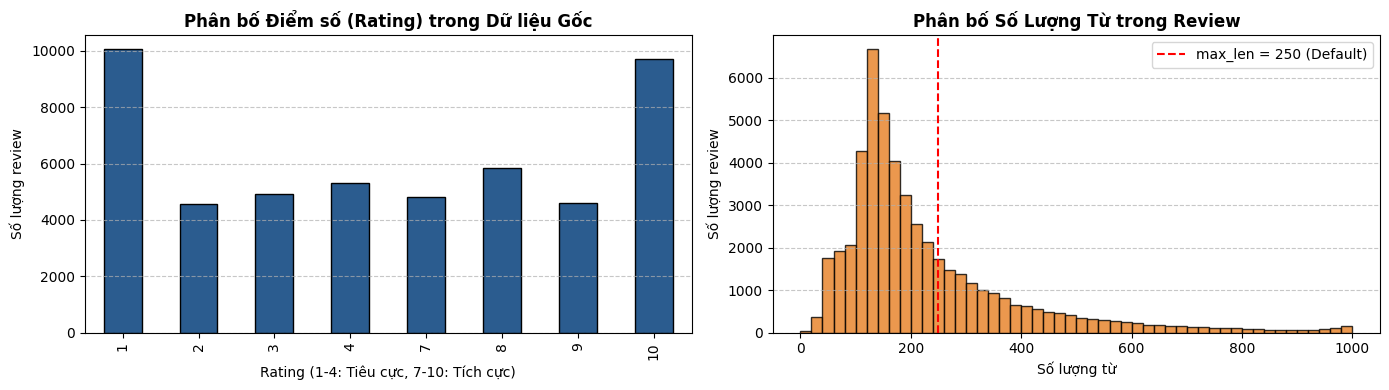

In [9]:
# 3. Trực quan hóa dữ liệu thật: Phân bố rating và chiều dài văn bản
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Biểu đồ rating gốc
full_df["rating"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#2b5c8f", edgecolor="black")
axes[0].set_title("Phân bố Điểm số (Rating) trong Dữ liệu Gốc", fontweight="bold")
axes[0].set_xlabel("Rating (1-4: Tiêu cực, 7-10: Tích cực)")
axes[0].set_ylabel("Số lượng review")
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

# Biểu đồ độ dài từ ước lượng
word_counts = full_df["text_clean"].str.split().str.len()
axes[1].hist(word_counts, bins=50, range=(0, 1000), color="#e67e22", edgecolor="black", alpha=0.8)
axes[1].axvline(250, color="red", linestyle="--", label="max_len = 250 (Default)")
axes[1].set_title("Phân bố Số Lượng Từ trong Review", fontweight="bold")
axes[1].set_xlabel("Số lượng từ")
axes[1].set_ylabel("Số lượng review")
axes[1].legend()
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()


## 3. Task D1: Pipeline Dữ liệu (Tokenizer, Vocab, Dataset, DataLoader)

**Nguyên tắc thiết kế cốt lõi:**
- **Tokenizer:** Lowercase, tách cụm phủ định `"n't"` thành token riêng biệt, giữ lại dấu chấm câu (`!`, `?`), **KHÔNG bỏ stopwords** (để mô hình chuỗi nhận diện được phủ định và cú pháp).
- **Vocab:** Xây dựng **CHỈ từ tập train** (22.306 mẫu), `min_freq=2`, `max_vocab_size=25000`. Special tokens: `<pad>=0`, `<unk>=1`.
- **Dataset / DataLoader:** Padding động theo từng batch, trả về độ dài thật (`lengths`) để dùng cho `pack_padded_sequence` trong RNN.


In [10]:
from src.data.dataset import IMDbDataset, create_dataloader, load_imdb_split_data
from src.data.tokenizer import tokenize
from src.data.vocab import Vocab

train_df = full_df[full_df["split"] == "train"].reset_index(drop=True)
val_df = full_df[full_df["split"] == "val"].reset_index(drop=True)
test_df = full_df[full_df["split"] == "test"].reset_index(drop=True)

# 1. Kiểm tra Tokenizer trên các mẫu đặc biệt
print("--- Ví dụ xử lý câu với Tokenizer (bảo toàn phủ định) ---")
examples = [
    "The acting wasn't bad, but the script wasn't good either!",
    "I haven't ever seen such a dreadful film. Absolutely not recommended?!",
    "It wasn't just entertaining; it was magnificent."
]
for ex in examples:
    print(f"Gốc   : {ex}")
    print(f"Tokens: {tokenize(ex)}")
    print()

# 2. Xây dựng Vocab CHỈ từ tập Train
vocab_file = PROJECT_ROOT / "data" / "processed" / "vocab.json"
train_tokens = [tokenize(t) for t in train_df["text_clean"]]
vocab = Vocab.build_from_tokens(train_tokens, min_freq=2, max_size=25000)
vocab.save(vocab_file)

print(f"✅ Vocab đã được xây dựng từ tập Train:")
print(f"   - Kích thước từ vựng: {len(vocab):,} từ")
print(f"   - Special tokens: <pad>={vocab.pad_idx}, <unk>={vocab.unk_idx}")
print(f"   - File lưu: {vocab_file}")


--- Ví dụ xử lý câu với Tokenizer (bảo toàn phủ định) ---
Gốc   : The acting wasn't bad, but the script wasn't good either!
Tokens: ['the', 'acting', 'was', "n't", 'bad', ',', 'but', 'the', 'script', 'was', "n't", 'good', 'either', '!']

Gốc   : I haven't ever seen such a dreadful film. Absolutely not recommended?!
Tokens: ['i', 'have', "n't", 'ever', 'seen', 'such', 'a', 'dreadful', 'film', '.', 'absolutely', 'not', 'recommended', '?', '!']

Gốc   : It wasn't just entertaining; it was magnificent.
Tokens: ['it', 'was', "n't", 'just', 'entertaining', ';', 'it', 'was', 'magnificent', '.']

✅ Vocab đã được xây dựng từ tập Train:
   - Kích thước từ vựng: 25,000 từ
   - Special tokens: <pad>=0, <unk>=1
   - File lưu: /content/LSTM_PJ/data/processed/vocab.json


In [11]:
# 3. Tạo DataLoader và kiểm tra tensor mini-batch
train_dataset = IMDbDataset(train_df["text_clean"], train_df["label"], train_df["uid"], train_df["rating"], vocab, max_len=250)
val_dataset = IMDbDataset(val_df["text_clean"], val_df["label"], val_df["uid"], val_df["rating"], vocab, max_len=250)
test_dataset = IMDbDataset(test_df["text_clean"], test_df["label"], test_df["uid"], test_df["rating"], vocab, max_len=250)

train_loader = create_dataloader(train_dataset, batch_size=64, shuffle=True)
val_loader = create_dataloader(val_dataset, batch_size=64, shuffle=False)
test_loader = create_dataloader(test_dataset, batch_size=64, shuffle=False)

sample_batch = next(iter(train_loader))
print("--- Cấu trúc một mini-batch thực tế từ Train DataLoader ---")
print("input_ids shape:", sample_batch["input_ids"].shape)
print("lengths shape  :", sample_batch["lengths"].shape)
print("labels shape   :", sample_batch["labels"].shape)
print("Độ dài tối đa batch này:", sample_batch["lengths"].max().item())


--- Cấu trúc một mini-batch thực tế từ Train DataLoader ---
input_ids shape: torch.Size([64, 250])
lengths shape  : torch.Size([64])
labels shape   : torch.Size([64])
Độ dài tối đa batch này: 250


## 4. Tasks D2 & D3: Kiến trúc Mô hình SentimentRNN & GloVe Embedding

**Đặc tả kỹ thuật theo `docs/MODELS.md`:**
```
nn.Embedding(vocab_size, 100, padding_idx=0)
  → pack_padded_sequence(input_ids, lengths, enforce_sorted=False)
  → nn.LSTM / nn.GRU (hidden_dim=128, num_layers=1, bidirectional=True/False)
  → Pooling (Last hidden state hoặc Attention Pooling)
  → nn.Dropout(0.5) → nn.Linear(hidden_dim, 1) → logit
```
- **M1 (LSTM 1 chiều):** LSTM 128 hidden, học từ đầu
- **M2 (GRU 1 chiều):** GRU 128 hidden, học từ đầu
- **M3 (BiLSTM 2 chiều):** LSTM 2 chiều (128x2 = 256 output), học từ đầu
- **M4a (BiLSTM + GloVe Đóng băng):** GloVe 100d, không cập nhật trọng số embedding
- **M4b (BiLSTM + GloVe Fine-tune):** GloVe 100d, cho phép cập nhật embedding
- **E1 (BiLSTM + Attention Pooling):** Cơ chế Attention học trọng số quan trọng từng token


In [12]:
from src.models.rnn import SentimentRNN
from src.models.glove import build_glove_matrix
import numpy as np

# Khởi tạo ma trận giả lập 100d tạm thời nếu chưa có file GloVe thật, để khởi dựng cấu trúc chính xác cho mô hình
try:
    glove_file = PROJECT_ROOT / "data" / "glove" / "glove.6B.100d.txt"
    if glove_file.exists():
        dummy_glove, _ = build_glove_matrix(vocab, glove_path=glove_file, embed_dim=100)
    else:
        dummy_glove = np.random.normal(scale=0.6, size=(len(vocab), 100))
except Exception:
    dummy_glove = np.random.normal(scale=0.6, size=(len(vocab), 100))

# 1. Bảng đếm tham số chính xác cho tất cả các mô hình
model_instances = {
    "M1: LSTM 1 chiều"               : SentimentRNN(len(vocab), 100, 128, rnn_type="lstm", bidirectional=False),
    "M2: GRU 1 chiều"                : SentimentRNN(len(vocab), 100, 128, rnn_type="gru", bidirectional=False),
    "M3: BiLSTM 2 chiều"             : SentimentRNN(len(vocab), 100, 128, rnn_type="lstm", bidirectional=True),
    "M4a: BiLSTM + GloVe (Đóng băng)": SentimentRNN(len(vocab), 100, 128, rnn_type="lstm", bidirectional=True, pretrained_embeddings=dummy_glove, freeze=True),
    "M4b: BiLSTM + GloVe (Fine-tune)": SentimentRNN(len(vocab), 100, 128, rnn_type="lstm", bidirectional=True, pretrained_embeddings=dummy_glove, freeze=False),
    "E1: BiLSTM + Attention"         : SentimentRNN(len(vocab), 100, 128, rnn_type="lstm", bidirectional=True, pooling="attention"),
}

param_table = []
for name, m in model_instances.items():
    counts = m.count_parameters()
    embedding_trainable = m.embedding.weight.requires_grad

    param_table.append({
        "Mô hình": name,
        "Tổng tham số": f"{counts.get('total', 0):,}",
        "Tham số huấn luyện": f"{counts.get('trainable', 0):,}",
        "Embedding Trainable": "Yes" if embedding_trainable else "No"
    })

display(pd.DataFrame(param_table))

2026-11-24 12:35:12,867 [INFO] Đang đọc GloVe từ /content/LSTM_PJ/data/glove/glove.6B.100d.txt...
2026-11-24 12:35:16,193 [INFO] GloVe coverage: 24678/24999 (98.72%)


,Mô hình,Tổng tham số,Tham số huấn luyện,Embedding Trainable
0,M1: LSTM 1 chiều,"2,617,889","2,617,889",Yes
1,M2: GRU 1 chiều,"2,588,449","2,588,449",Yes
2,M3: BiLSTM 2 chiều,"2,735,777","2,735,777",Yes
3,M4a: BiLSTM + GloVe (Đóng băng),"2,735,777","235,777",No
4,M4b: BiLSTM + GloVe (Fine-tune),"2,735,777","2,735,777",Yes
5,E1: BiLSTM + Attention,"2,768,802","2,768,802",Yes


In [13]:
# 2. Xây dựng và LƯU ma trận GloVe Embedding (Task D3 -> data/processed/glove_100d_vocab.npy)
glove_file = PROJECT_ROOT / "data" / "glove" / "glove.6B.100d.txt"
glove_npy = PROJECT_ROOT / "data" / "processed" / "glove_100d_vocab.npy"

if glove_file.exists():
    print(f"📖 Tìm thấy file GloVe tại {glove_file}. Đang trích xuất ma trận theo từ vựng...")
    glove_matrix, coverage = build_glove_matrix(
        vocab,
        glove_path=glove_file,
        embed_dim=100,
        output_path=glove_npy,
    )
    print(f"✅ GloVe matrix đã được tạo và lưu tại: {glove_npy}")
    print(f"   Shape: {glove_matrix.shape} | Tỷ lệ phủ (coverage): {coverage*100:.2f}%")
else:
    print(f"⚠️ Chưa có file GloVe tại {glove_file}.")
    print("   -> Khởi tạo ma trận ngẫu nhiên fallback (allow_random=True) để chạy thử nghiệm.")
    glove_matrix, coverage = build_glove_matrix(
        vocab,
        glove_path=None,
        embed_dim=100,
        output_path=glove_npy,
        allow_random=True,
    )
    print(f"   Shape: {glove_matrix.shape} | Đã lưu fallback tại: {glove_npy}")


2026-11-24 12:35:16,384 [INFO] Đang đọc GloVe từ /content/LSTM_PJ/data/glove/glove.6B.100d.txt...


📖 Tìm thấy file GloVe tại /content/LSTM_PJ/data/glove/glove.6B.100d.txt. Đang trích xuất ma trận theo từ vựng...


2026-11-24 12:35:20,800 [INFO] GloVe coverage: 24678/24999 (98.72%)
2026-11-24 12:35:20,808 [INFO] Đã lưu ma trận GloVe vào /content/LSTM_PJ/data/processed/glove_100d_vocab.npy


✅ GloVe matrix đã được tạo và lưu tại: /content/LSTM_PJ/data/processed/glove_100d_vocab.npy
   Shape: (25000, 100) | Tỷ lệ phủ (coverage): 98.72%


In [14]:
# 3. Sanity Check: Overfit 1 batch nhỏ để xác nhận gradients (Task D2)
print("🧪 Sanity check: Kiểm tra khả năng overfit trên 1 batch...")
sanity_model = SentimentRNN(len(vocab), 100, 128, rnn_type="lstm").to(device)
sanity_opt = torch.optim.Adam(sanity_model.parameters(), lr=0.01)
sanity_crit = nn.BCEWithLogitsLoss()

b_x = sample_batch["input_ids"].to(device)
b_len = sample_batch["lengths"]
b_y = sample_batch["labels"].to(device)

loss_history = []
for step in range(40):
    sanity_opt.zero_grad()
    logits = sanity_model(b_x, b_len)
    loss = sanity_crit(logits, b_y)
    loss.backward()
    sanity_opt.step()
    loss_history.append(loss.item())

print(f"   Loss bước 1: {loss_history[0]:.4f} -> Loss bước 40: {loss_history[-1]:.4f}")
assert loss_history[-1] < loss_history[0] * 0.2, "LỖI: Mô hình không giảm loss trên 1 batch!"
print("✅ Sanity Check PASSED: Mô hình học bình thường và gradients hoạt động chính xác.")


🧪 Sanity check: Kiểm tra khả năng overfit trên 1 batch...
   Loss bước 1: 0.7001 -> Loss bước 40: 0.0000
✅ Sanity Check PASSED: Mô hình học bình thường và gradients hoạt động chính xác.


## 5. Mô hình Baseline B0 (Majority) & B1 (TF-IDF + Logistic Regression)

Theo `docs/phases/BASELINE.md` và `docs/TASKS.md` §3 (B5, D8):
- Cần có kết quả của Baseline để làm mốc đối chứng và thực hiện **kiểm định thống kê McNemar**.
- **M0a (Majority):** Đoán nhãn chiếm đa số trong train (~50%).
- **M0b (TF-IDF + LR):** `TfidfVectorizer(ngram_range=(1,2), min_df=2)` + `LogisticRegression`, quét tìm $C \in [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]$ tối ưu trên validation set.


In [15]:
from src.models.baseline import BaselineRunner

print("🚀 Huấn luyện Baseline B0 & B1 (chỉ hiển thị kết quả Validation trước khi chốt mô hình ở D8)...")
baseline_runner = BaselineRunner()

# Chạy M0a (Majority) — tự lưu experiments/results/majority/{val,test}_metrics.json
m0a_results = baseline_runner.run_majority_baseline()

# Chạy M0b (TF-IDF + LR) — chọn C trên val, lưu artifacts để đối chiếu ở D8
m0b_results = baseline_runner.run_tfidf_lr_baseline(
    c_candidates=[0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
    save_artifacts=True,
)

baseline_val_df = pd.DataFrame([
    {
        "Mô hình": "M0a: Majority Class",
        "Val Accuracy": f"{m0a_results['val_metrics']['accuracy']*100:.2f}%",
        "Val Macro-F1": f"{m0a_results['val_metrics']['macro_f1']:.4f}",
        "Ghi chú": f"Nhãn đa số = {m0a_results['majority_label']}",
    },
    {
        "Mô hình": "M0b: TF-IDF (1-2 gram) + LR",
        "Val Accuracy": f"{m0b_results['val_metrics']['accuracy']*100:.2f}%",
        "Val Macro-F1": f"{m0b_results['val_metrics']['macro_f1']:.4f}",
        "Ghi chú": f"C tối ưu (trên Val) = {m0b_results['best_c']}",
    },
])
display(baseline_val_df)
print("ℹ️ Kết quả Test của Baseline sẽ được tổng hợp chung với các mô hình RNN ở Mục 8 (Task D8).")


🚀 Huấn luyện Baseline B0 & B1 (chỉ hiển thị kết quả Validation trước khi chốt mô hình ở D8)...


2026-11-24 12:35:34,309 [INFO] Chạy Baseline M0a (Majority Class)...
2026-11-24 12:35:34,310 [INFO] Nhãn đa số trong train: 1
2026-11-24 12:35:34,330 [INFO] M0a val Acc: 49.94%
2026-11-24 12:35:34,362 [INFO] M0a test Acc: 50.00%
2026-11-24 12:35:34,364 [INFO] Khởi tạo TfidfVectorizer (ngram_range=(1, 2), min_df=2)...
2026-11-24 12:35:34,365 [INFO] Fit TF-IDF trên tập train...
2026-11-24 12:35:50,182 [INFO] C=0.1   -> Val Acc: 86.13%
2026-11-24 12:35:51,088 [INFO] C=0.5   -> Val Acc: 88.15%
2026-11-24 12:35:52,632 [INFO] C=1.0   -> Val Acc: 89.16%
2026-11-24 12:35:54,886 [INFO] C=2.0   -> Val Acc: 89.24%
2026-11-24 12:35:57,241 [INFO] C=5.0   -> Val Acc: 89.81%
2026-11-24 12:36:02,286 [INFO] C=10.0  -> Val Acc: 89.69%
2026-11-24 12:36:02,291 [INFO] Chọn C tối ưu: 5.0 với Val Acc: 89.81%
2026-11-24 12:36:14,815 [INFO] Đã lưu mô hình M0b vào experiments/checkpoints/baseline_tfidf_lr.joblib
2026-11-24 12:36:15,391 [INFO] Đã lưu dự đoán val tại experiments/results/baseline/predictions_val.c

,Mô hình,Val Accuracy,Val Macro-F1,Ghi chú
0,M0a: Majority Class,49.94%,0.3331,Nhãn đa số = 1
1,M0b: TF-IDF (1-2 gram) + LR,89.81%,0.8981,C tối ưu (trên Val) = 5.0


ℹ️ Kết quả Test của Baseline sẽ được tổng hợp chung với các mô hình RNN ở Mục 8 (Task D8).


## 6. Tasks D4, D5, D6: Huấn luyện Đầy đủ & Giám sát (Monitor)

**Quy chuẩn thực nghiệm:**
- **Mỗi cấu hình huấn luyện qua 3 seeds độc lập:** `42`, `123`, `2025` (để tính mean ± std theo chuẩn M6).
- **Hàm mất mát:** `nn.BCEWithLogitsLoss`.
- **Tối ưu hóa:** `Adam(lr=0.001, weight_decay=1e-5)` kèm Gradient Clipping tại `5.0`.
- **Early Stopping & Lưu Checkpoint:** Theo dõi **Validation Accuracy** (patience = 3, max_epochs = 10). Lưu checkpoint tốt nhất tại `best.pt`.
- **Monitor:** Ghi log từng epoch vào `experiments/runs/<exp>/seed_<s>/history.csv` và tự động vẽ learning curve.

> ⚙️ **Thiết lập chế độ chạy:**  
> - Khi chạy trên Kaggle/Colab GPU: Giữ `SAMPLE_MODE = False` (chạy 100% dữ liệu thật).  
> - Khi chạy thử nghiệm nhanh trên CPU: Đặt `SAMPLE_MODE = True` (chạy 1.000 mẫu).


In [16]:
from src.train import run_training
from src.training.monitor import aggregate_experiment_seeds, plot_learning_curves

# =========================================================================
# ĐIỀU KHIỂN CHẾ ĐỘ THỰC NGHIỆM
# =========================================================================
SAMPLE_MODE = False   # False = Chạy toàn bộ dữ liệu thật; True = Chạy thử 1.000 mẫu
SAMPLE_SIZE = 1000 if SAMPLE_MODE else None

CONFIG_LIST = [
    "configs/lstm.yaml",                # M1: LSTM 1 chiều
    "configs/gru.yaml",                 # M2: GRU 1 chiều
    "configs/bilstm.yaml",              # M3: BiLSTM 2 chiều
    "configs/bilstm_glove_frozen.yaml", # M4a: BiLSTM + GloVe Đóng băng
    "configs/bilstm_glove_ft.yaml",     # M4b: BiLSTM + GloVe Fine-tune
    "configs/bilstm_attention.yaml",    # E1: BiLSTM + Attention Pooling
]

EXPERIMENT_SEEDS = [42, 123, 2025]

print(f"🚀 BẮT ĐẦU HUẤN LUYỆN:")
print(f"   - Chế độ: {'THỬ NGHIỆM (1.000 mẫu)' if SAMPLE_MODE else 'TOÀN BỘ DỮ LIỆU THẬT (22.306 train / 2.473 val)'}")
print(f"   - Cấu hình ({len(CONFIG_LIST)} mô hình): {[Path(c).stem for c in CONFIG_LIST]}")
print(f"   - Seeds: {EXPERIMENT_SEEDS}")


🚀 BẮT ĐẦU HUẤN LUYỆN:
   - Chế độ: TOÀN BỘ DỮ LIỆU THẬT (22.306 train / 2.473 val)
   - Cấu hình (6 mô hình): ['lstm', 'gru', 'bilstm', 'bilstm_glove_frozen', 'bilstm_glove_ft', 'bilstm_attention']
   - Seeds: [42, 123, 2025]


In [17]:
# =========================================================================
# TASK D5 — PILOT M1 (LSTM): KIỂM TRA MỐC VAL ACC >= 85% TRƯỚC KHI CHẠY FULL
# =========================================================================
# Theo docs/phases/TRAINING.md: Mốc pilot M1 (LSTM) >= 85% trên val;
# nếu chưa đạt ở config mặc định (max_len=250, max_epochs=10), kiểm tra hội tụ / thử grid nhỏ.
RUN_D5_PILOT = True

if RUN_D5_PILOT:
    print("🧪 [Task D5] Chạy Pilot M1 (LSTM, seed=42)...")
    pilot_res = run_training(
        config_path=PROJECT_ROOT / "configs" / "lstm.yaml",
        seed=42,
        exp_name_override="pilot_lstm",
        sample_size=SAMPLE_SIZE,
    )
    pilot_val_acc = pilot_res["best_val_acc"] * 100
    print(f"📌 Kết quả Pilot M1: Val Acc = {pilot_val_acc:.2f}% (Best Epoch = {pilot_res['best_epoch']})")
    if pilot_val_acc >= 85.0:
        print("✅ ĐẠT MỐC D5 (LSTM >= 85% trên val)! Tiến hành huấn luyện đầy đủ D6.")
    else:
        print("⚠️ CHƯA ĐẠT MỐC 85% trên val với cấu hình mặc định (max_len=250, max_epochs=10).")
        print("   Gợi ý: tăng max_epochs lên 15, tăng max_len lên 400 hoặc giảm dropout xuống 0.3 trong configs/*.yaml rồi chạy lại.")


2026-11-24 12:36:20,458 [INFO] Bắt đầu huấn luyện thí nghiệm 'pilot_lstm' với seed 42...
2026-11-24 12:36:20,468 [INFO] Sử dụng thiết bị: cuda (Tesla T4)


🧪 [Task D5] Chạy Pilot M1 (LSTM, seed=42)...


2026-11-24 12:36:21,702 [INFO] Số lượng mẫu: train=22306, val=2473
2026-11-24 12:36:21,704 [INFO] Xây dựng từ vựng từ 22306 review train...
2026-11-24 12:36:28,157 [INFO] Đã lưu từ vựng (25000 từ) vào /content/LSTM_PJ/LSTM_PJ/experiments/checkpoints/pilot_lstm/vocab.json
2026-11-24 12:36:28,198 [INFO] Mô hình: 2,617,889 tham số (trainable: 2,617,889)
2026-11-24 12:36:28,201 [INFO] Bắt đầu huấn luyện tối đa 10 epochs (patience=3)...
2026-11-24 12:36:41,568 [INFO] Epoch 01/10 | Train Loss: 0.6733 Acc: 0.5716 | Val Loss: 0.6196 Acc: 0.6619 F1: 0.6659 ★ (Best) | Grad: 0.33 | Time: 13.4s
2026-11-24 12:36:55,619 [INFO] Epoch 02/10 | Train Loss: 0.6244 Acc: 0.6580 | Val Loss: 0.5898 Acc: 0.6975 F1: 0.6881 ★ (Best) | Grad: 1.20 | Time: 14.0s
2026-11-24 12:37:08,352 [INFO] Epoch 03/10 | Train Loss: 0.5517 Acc: 0.7291 | Val Loss: 0.5258 Acc: 0.7461 F1: 0.7586 ★ (Best) | Grad: 0.70 | Time: 12.7s
2026-11-24 12:37:21,197 [INFO] Epoch 04/10 | Train Loss: 0.4892 Acc: 0.7780 | Val Loss: 0.4914 Acc: 0.

📌 Kết quả Pilot M1: Val Acc = 81.08% (Best Epoch = 5)
⚠️ CHƯA ĐẠT MỐC 85% trên val với cấu hình mặc định (max_len=250, max_epochs=10).
   Gợi ý: tăng max_epochs lên 15, tăng max_len lên 400 hoặc giảm dropout xuống 0.3 trong configs/*.yaml rồi chạy lại.


In [18]:
from src.training.monitor import aggregate_experiment_seeds, plot_learning_curves

# Vòng lặp huấn luyện toàn bộ cấu hình qua 3 seeds (Task D6 + E1)
plots_training_dir = PROJECT_ROOT / "experiments" / "plots" / "training"
plots_training_dir.mkdir(parents=True, exist_ok=True)

for cfg_rel in CONFIG_LIST:
    cfg_path = PROJECT_ROOT / cfg_rel
    exp_name = cfg_path.stem
    print(f"\n{'='*75}")
    print(f"🎯 BẮT ĐẦU MÔ HÌNH: {exp_name.upper()}")
    print(f"{'='*75}")

    for seed in EXPERIMENT_SEEDS:
        print(f"\n>>> Huấn luyện {exp_name} | Seed {seed}...")
        run_training(
            config_path=cfg_path,
            seed=seed,
            sample_size=SAMPLE_SIZE,
            epochs_override=None,
        )

    summary = aggregate_experiment_seeds(exp_name, seeds=EXPERIMENT_SEEDS)
    val_acc_info = summary.get("best_val_acc", {})
    mean_acc = val_acc_info.get("mean", 0.0) * 100
    std_acc = val_acc_info.get("std", 0.0) * 100
    print(f"\n✅ Hoàn tất 3 seed cho {exp_name}! Val Accuracy (Mean ± Std): {mean_acc:.2f} ± {std_acc:.2f}%")


2026-11-24 12:38:14,497 [INFO] Bắt đầu huấn luyện thí nghiệm 'lstm' với seed 42...
2026-11-24 12:38:14,500 [INFO] Sử dụng thiết bị: cuda (Tesla T4)



🎯 BẮT ĐẦU MÔ HÌNH: LSTM

>>> Huấn luyện lstm | Seed 42...


2026-11-24 12:38:15,713 [INFO] Số lượng mẫu: train=22306, val=2473
2026-11-24 12:38:15,715 [INFO] Xây dựng từ vựng từ 22306 review train...
2026-11-24 12:38:20,870 [INFO] Đã lưu từ vựng (25000 từ) vào /content/LSTM_PJ/LSTM_PJ/experiments/checkpoints/lstm/vocab.json
2026-11-24 12:38:20,921 [INFO] Mô hình: 2,617,889 tham số (trainable: 2,617,889)
2026-11-24 12:38:20,923 [INFO] Bắt đầu huấn luyện tối đa 10 epochs (patience=3)...
2026-11-24 12:38:33,495 [INFO] Epoch 01/10 | Train Loss: 0.6733 Acc: 0.5716 | Val Loss: 0.6196 Acc: 0.6619 F1: 0.6659 ★ (Best) | Grad: 0.33 | Time: 12.6s
2026-11-24 12:38:46,765 [INFO] Epoch 02/10 | Train Loss: 0.6244 Acc: 0.6580 | Val Loss: 0.5898 Acc: 0.6975 F1: 0.6881 ★ (Best) | Grad: 1.20 | Time: 13.2s
2026-11-24 12:38:59,701 [INFO] Epoch 03/10 | Train Loss: 0.5517 Acc: 0.7291 | Val Loss: 0.5258 Acc: 0.7461 F1: 0.7586 ★ (Best) | Grad: 0.70 | Time: 12.9s
2026-11-24 12:39:12,694 [INFO] Epoch 04/10 | Train Loss: 0.4892 Acc: 0.7780 | Val Loss: 0.4914 Acc: 0.7780 F


>>> Huấn luyện lstm | Seed 123...


2026-11-24 12:40:05,616 [INFO] Số lượng mẫu: train=22306, val=2473
2026-11-24 12:40:05,618 [INFO] Tải từ vựng có sẵn từ /content/LSTM_PJ/LSTM_PJ/experiments/checkpoints/lstm/vocab.json
2026-11-24 12:40:05,695 [INFO] Mô hình: 2,617,889 tham số (trainable: 2,617,889)
2026-11-24 12:40:05,696 [INFO] Bắt đầu huấn luyện tối đa 10 epochs (patience=3)...
2026-11-24 12:40:18,493 [INFO] Epoch 01/10 | Train Loss: 0.6862 Acc: 0.5513 | Val Loss: 0.6774 Acc: 0.5673 F1: 0.5474 ★ (Best) | Grad: 0.41 | Time: 12.8s
2026-11-24 12:40:31,691 [INFO] Epoch 02/10 | Train Loss: 0.6519 Acc: 0.6196 | Val Loss: 0.6195 Acc: 0.6599 F1: 0.6549 ★ (Best) | Grad: 0.51 | Time: 13.2s
2026-11-24 12:40:44,792 [INFO] Epoch 03/10 | Train Loss: 0.5908 Acc: 0.7039 | Val Loss: 0.5531 Acc: 0.7380 F1: 0.7391 ★ (Best) | Grad: 1.13 | Time: 13.1s
2026-11-24 12:40:57,815 [INFO] Epoch 04/10 | Train Loss: 0.5093 Acc: 0.7631 | Val Loss: 0.5183 Acc: 0.7493 F1: 0.7482 ★ (Best) | Grad: 1.31 | Time: 13.0s
2026-11-24 12:41:10,434 [INFO] Epoc


>>> Huấn luyện lstm | Seed 2025...


... (28 outputs left out)

2026-11-24 13:15:02,340 [INFO] Số lượng mẫu: train=22306, val=2473
2026-11-24 13:15:02,343 [INFO] Tải từ vựng có sẵn từ /content/LSTM_PJ/LSTM_PJ/experiments/checkpoints/bilstm_attention/vocab.json
2026-11-24 13:15:02,428 [INFO] Mô hình: 2,768,802 tham số (trainable: 2,768,802)
2026-11-24 13:15:02,430 [INFO] Bắt đầu huấn luyện tối đa 10 epochs (patience=3)...
2026-11-24 13:15:22,167 [INFO] Epoch 01/10 | Train Loss: 0.5256 Acc: 0.7289 | Val Loss: 0.4233 Acc: 0.8079 F1: 0.8178 ★ (Best) | Grad: 0.50 | Time: 19.7s
2026-11-24 13:15:42,491 [INFO] Epoch 02/10 | Train Loss: 0.3392 Acc: 0.8542 | Val Loss: 0.3523 Acc: 0.8362 F1: 0.8446 ★ (Best) | Grad: 0.59 | Time: 20.3s
2026-11-24 13:16:01,999 [INFO] Epoch 03/10 | Train Loss: 0.2514 Acc: 0.9006 | Val Loss: 0.3400 Acc: 0.8492 F1: 0.8390 ★ (Best) | Grad: 0.61 | Time: 19.5s
2026-11-24 13:16:22,377 [INFO] Epoch 04/10 | Train Loss: 0.1941 Acc: 0.9252 | Val Loss: 0.3205 Acc: 0.8625 F1: 0.8652 ★ (Best) | Grad: 0.67 | Time: 20.4s
2026-11-24 13:16:42,117


>>> Huấn luyện bilstm_attention | Seed 2025...


2026-11-24 13:17:25,346 [INFO] Số lượng mẫu: train=22306, val=2473
2026-11-24 13:17:25,347 [INFO] Tải từ vựng có sẵn từ /content/LSTM_PJ/LSTM_PJ/experiments/checkpoints/bilstm_attention/vocab.json
2026-11-24 13:17:25,398 [INFO] Mô hình: 2,768,802 tham số (trainable: 2,768,802)
2026-11-24 13:17:25,399 [INFO] Bắt đầu huấn luyện tối đa 10 epochs (patience=3)...
2026-11-24 13:17:45,452 [INFO] Epoch 01/10 | Train Loss: 0.5279 Acc: 0.7234 | Val Loss: 0.4315 Acc: 0.7901 F1: 0.8066 ★ (Best) | Grad: 0.45 | Time: 20.1s
2026-11-24 13:18:06,130 [INFO] Epoch 02/10 | Train Loss: 0.3439 Acc: 0.8506 | Val Loss: 0.3541 Acc: 0.8387 F1: 0.8398 ★ (Best) | Grad: 0.59 | Time: 20.7s
2026-11-24 13:18:25,935 [INFO] Epoch 03/10 | Train Loss: 0.2572 Acc: 0.8961 | Val Loss: 0.3329 Acc: 0.8492 F1: 0.8532 ★ (Best) | Grad: 0.56 | Time: 19.8s
2026-11-24 13:18:46,696 [INFO] Epoch 04/10 | Train Loss: 0.1919 Acc: 0.9294 | Val Loss: 0.3376 Acc: 0.8560 F1: 0.8604 ★ (Best) | Grad: 0.62 | Time: 20.7s
2026-11-24 13:19:06,462


✅ Hoàn tất 3 seed cho bilstm_attention! Val Accuracy (Mean ± Std): 86.14 ± 0.41%


📈 Learning Curves: lstm


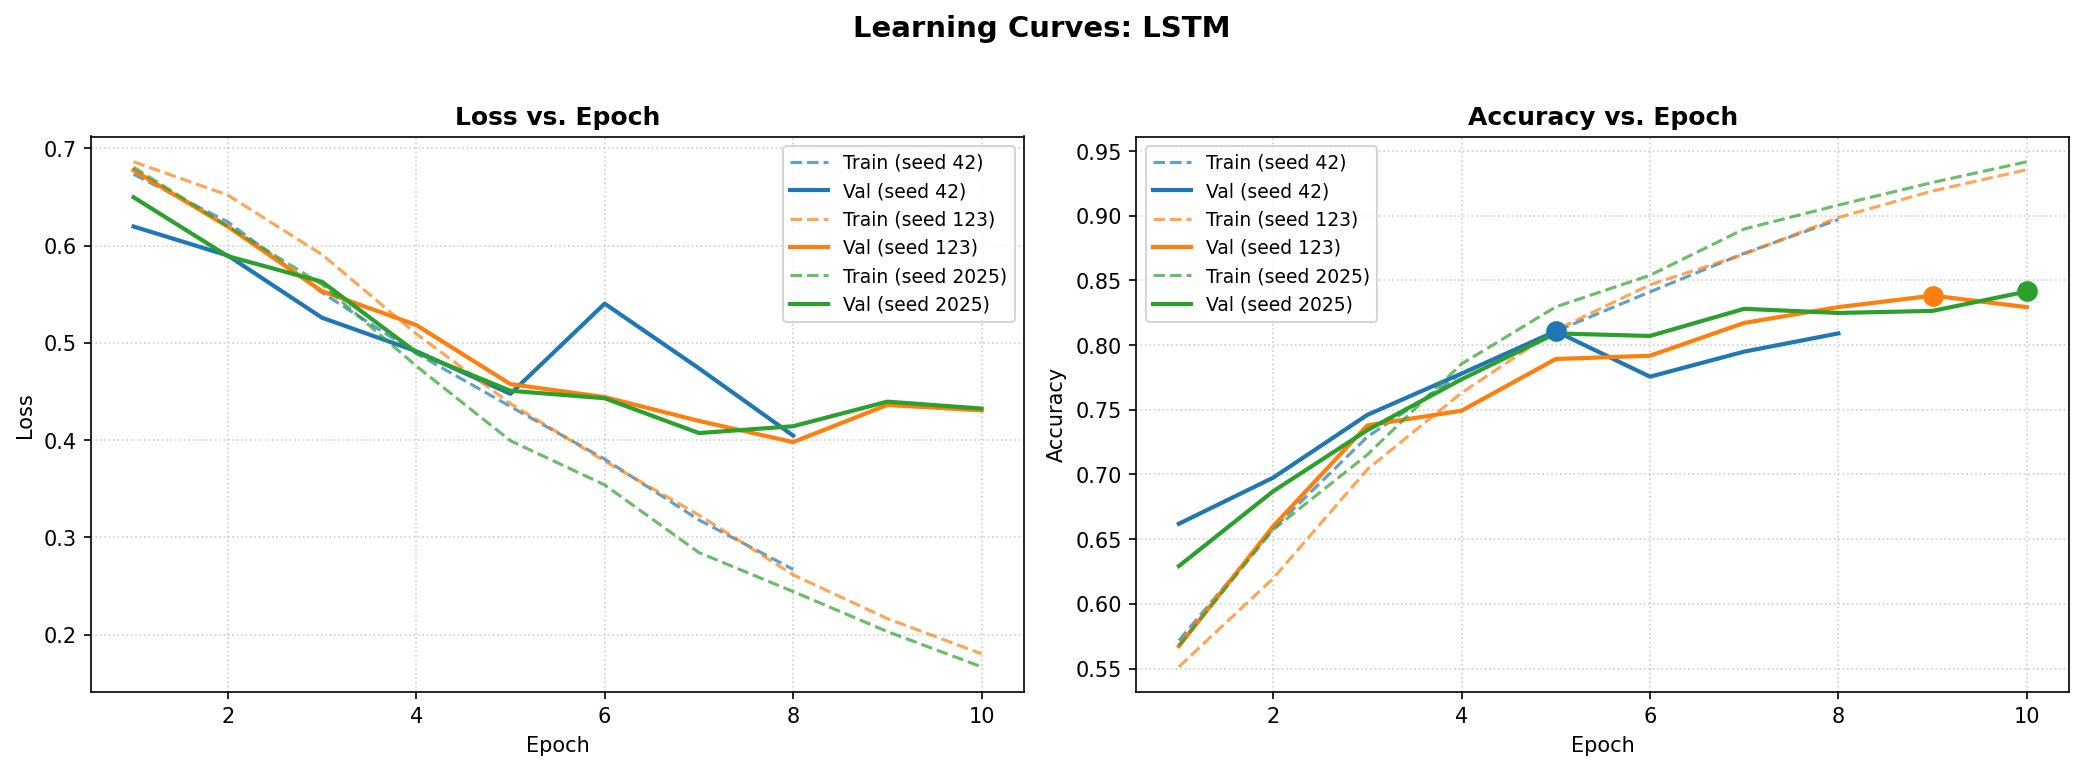

📈 Learning Curves: gru


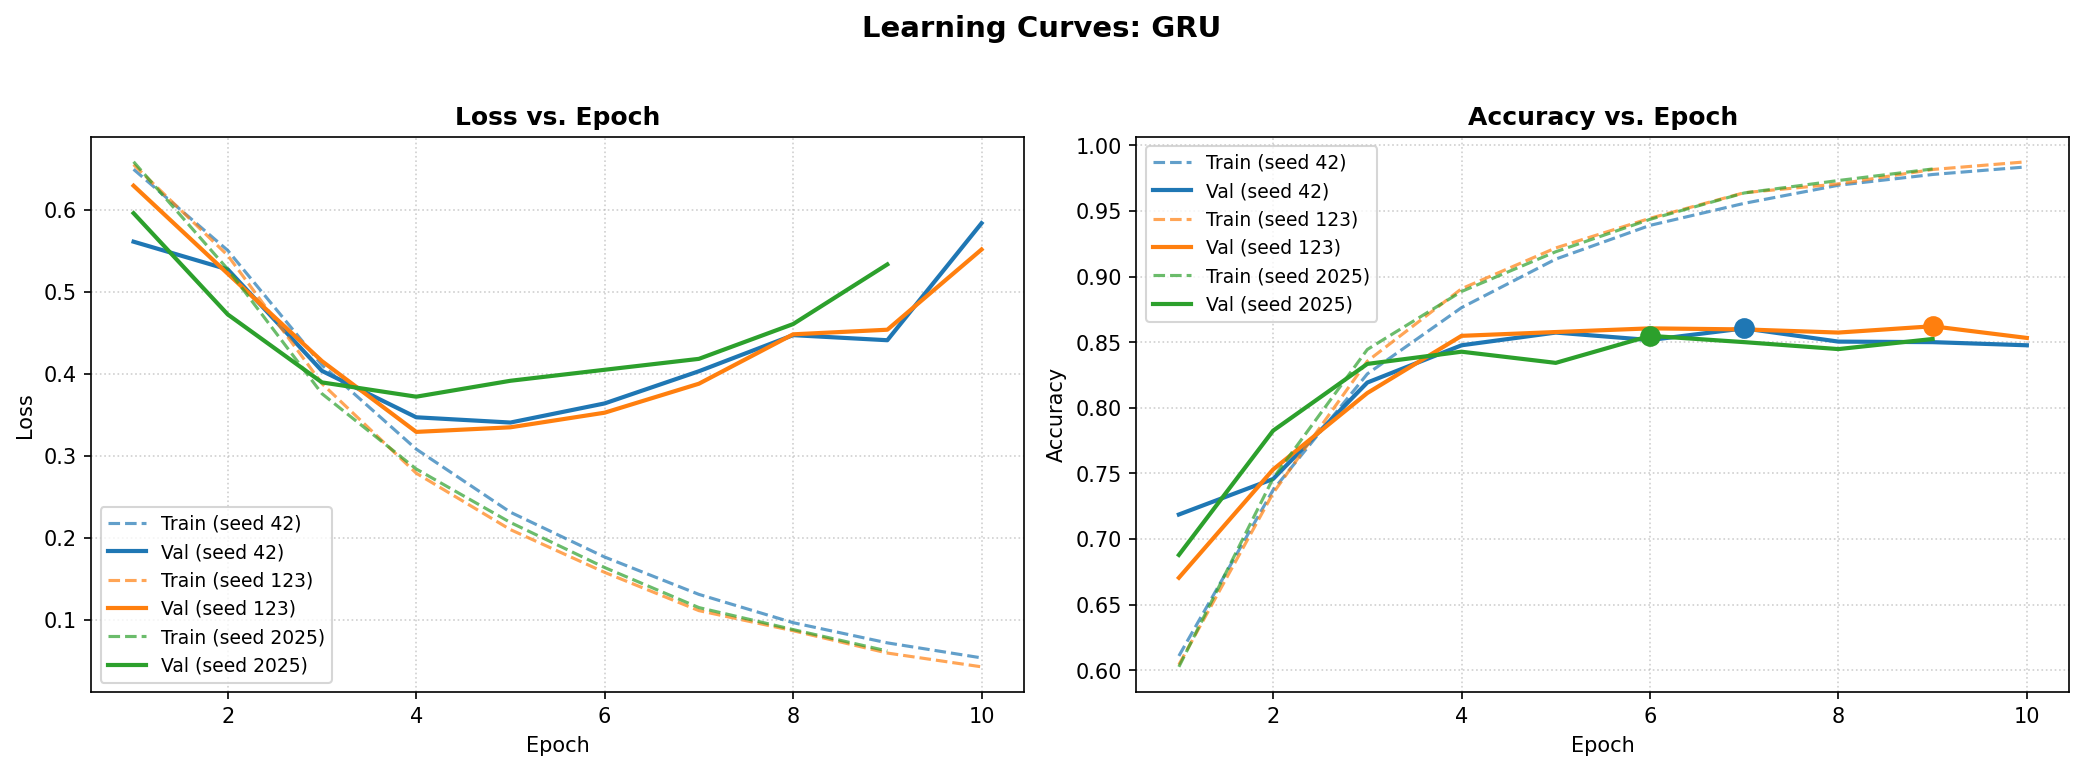

📈 Learning Curves: bilstm


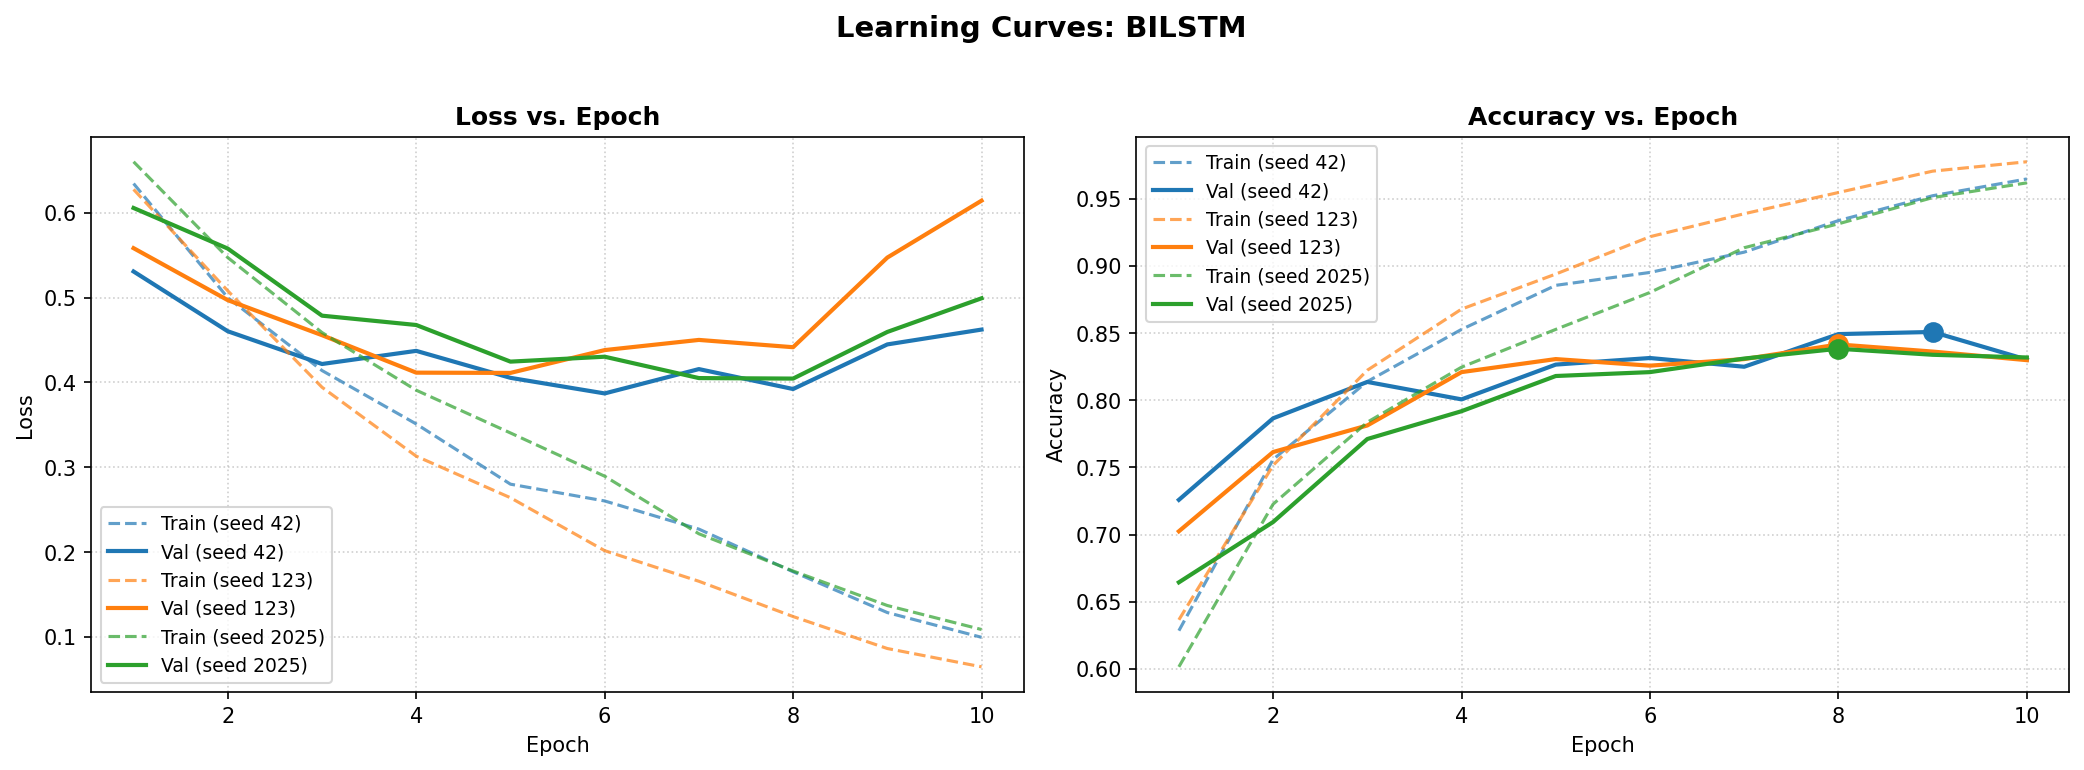

📈 Learning Curves: bilstm_glove_frozen


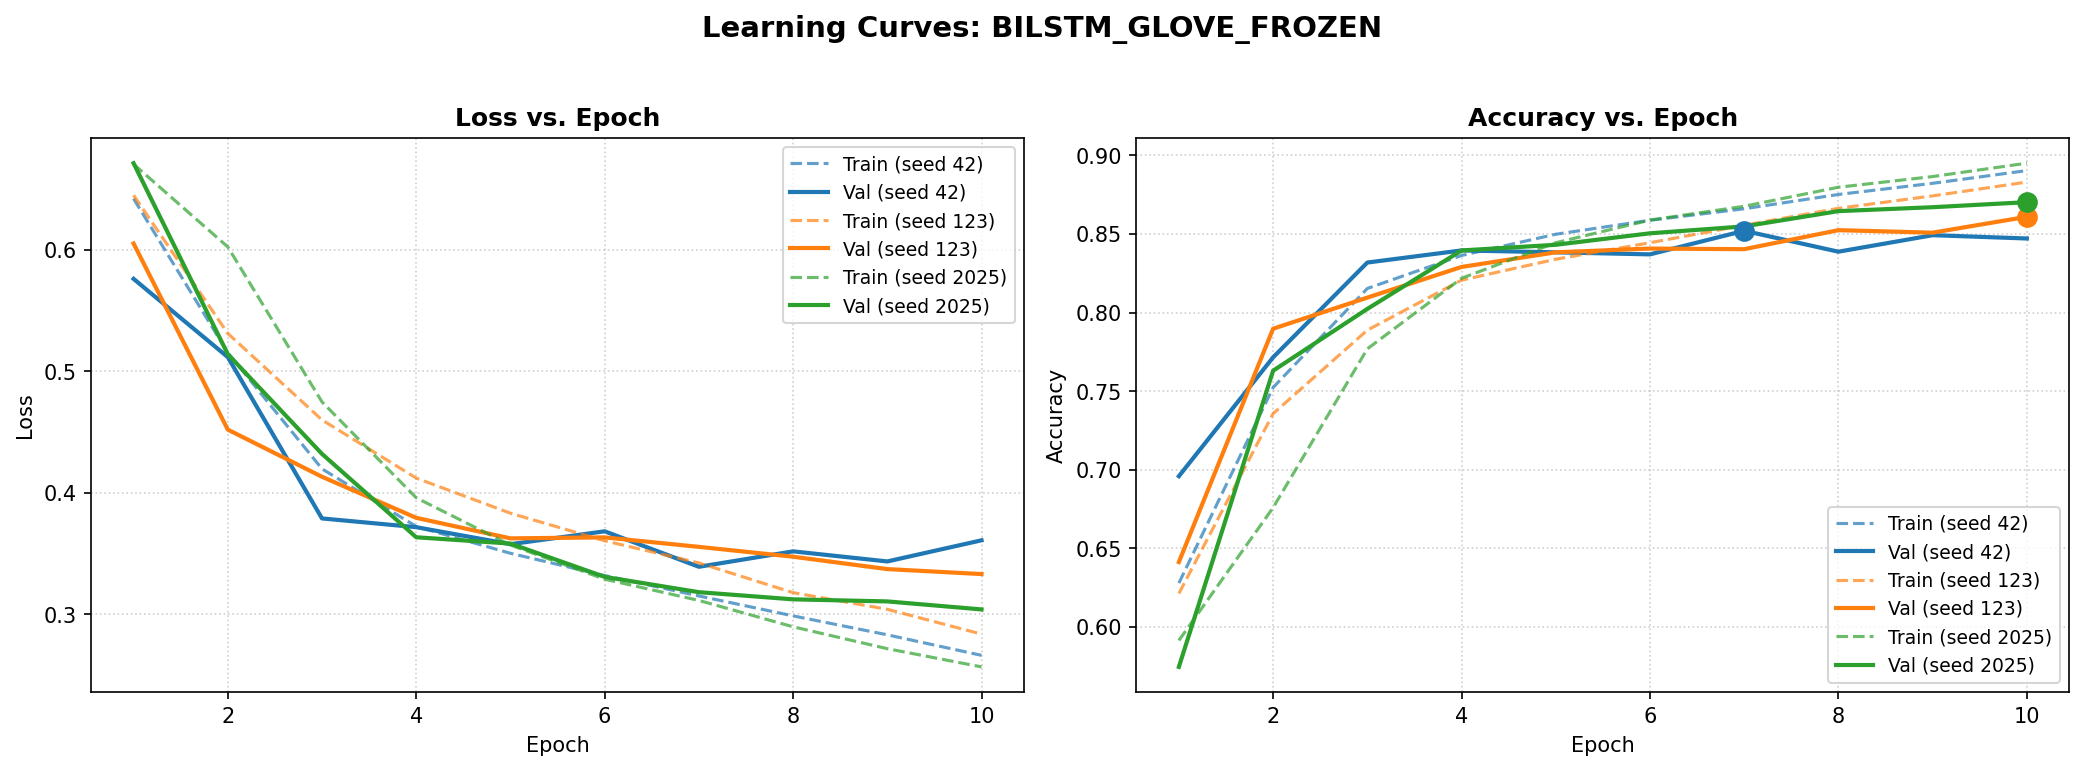

📈 Learning Curves: bilstm_glove_ft


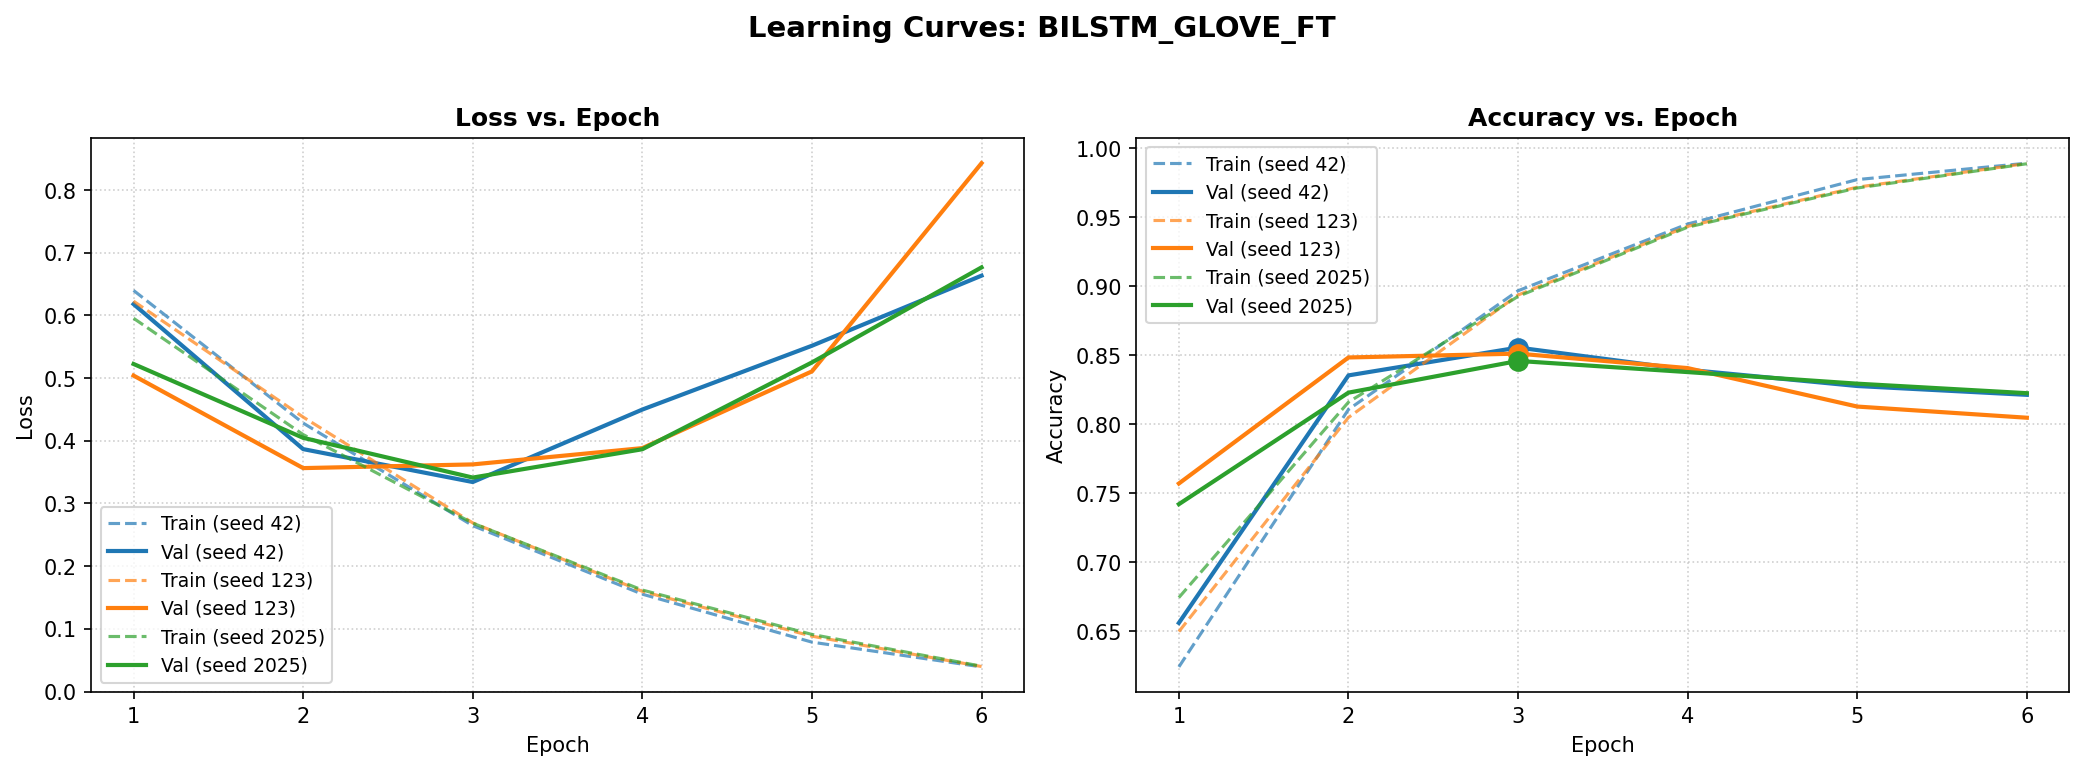

📈 Learning Curves: bilstm_attention


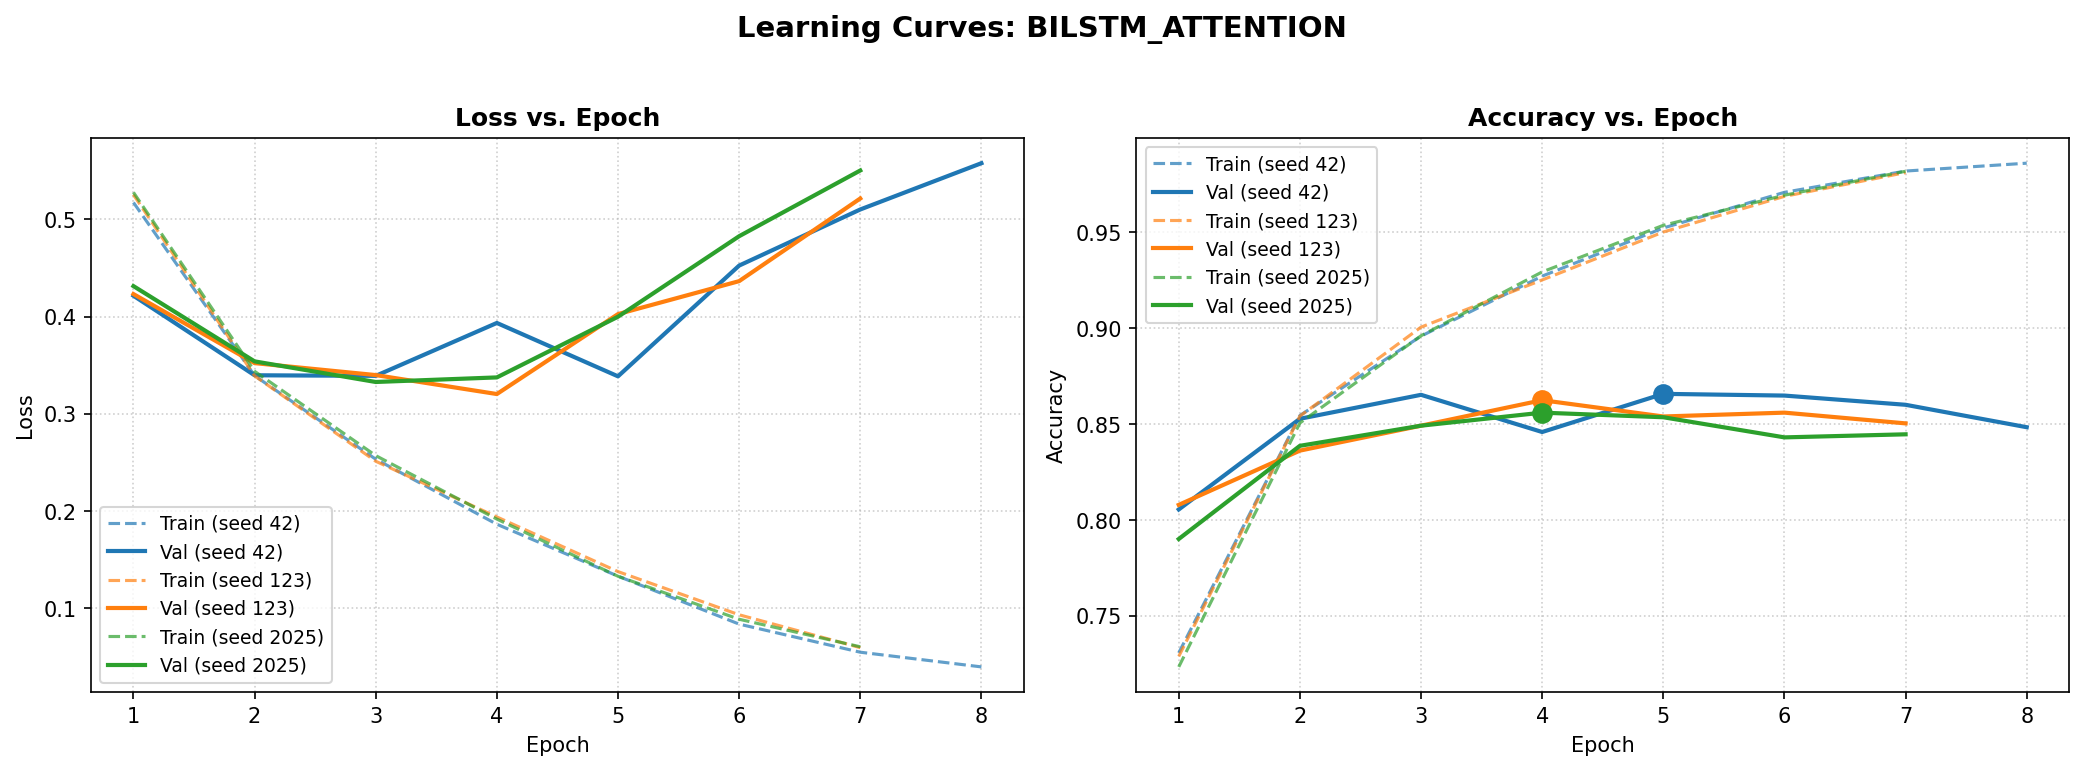

In [19]:
# Hiển thị trực quan Learning Curves của các mô hình đã huấn luyện
from IPython.display import Image, display

plots_training_dir = PROJECT_ROOT / "experiments" / "plots" / "training"
for cfg_rel in CONFIG_LIST:
    exp_name = Path(cfg_rel).stem
    img_path = plots_training_dir / f"{exp_name}_curves.png"
    if img_path.exists():
        print(f"📈 Learning Curves: {exp_name}")
        display(Image(filename=str(img_path)))


In [20]:
# =========================================================================
# TASK D6 — BẢNG SO SÁNH VALIDATION (comparison_val.csv) & CHẨN ĐOÁN MONITOR
# =========================================================================
from src.evaluate import compare_all_models

# 1. Xuất bảng so sánh tổng hợp trên tập Validation (gồm majority, baseline B1, M1-M4b, E1)
val_comparison_df = compare_all_models(
    results_base=PROJECT_ROOT / "experiments" / "results",
    split="val",
)
print("🏆 BẢNG SO SÁNH TỔNG HỢP TRÊN TẬP VALIDATION (experiments/results/comparison_val.csv):")
display(val_comparison_df)

# 2. Bảng chẩn đoán Monitor (best_epoch, stopped_epoch, overfit gap, thời gian train)
monitor_rows = []
BEST_RNN_EXP = None
BEST_RNN_MEAN_VAL = -1.0
BEST_SEED_BY_EXP = {}

for cfg_rel in CONFIG_LIST:
    exp_name = Path(cfg_rel).stem
    best_s_acc = -1.0
    best_s = EXPERIMENT_SEEDS[0]
    seed_val_accs = []

    for seed in EXPERIMENT_SEEDS:
        m_path = PROJECT_ROOT / "experiments" / "results" / exp_name / f"seed_{seed}" / "metrics.json"
        if not m_path.exists():
            continue
        m = json.loads(m_path.read_text(encoding="utf-8"))
        val_acc = float(m.get("best_val_acc", 0.0))
        seed_val_accs.append(val_acc)
        if val_acc > best_s_acc:
            best_s_acc = val_acc
            best_s = seed

        monitor_rows.append({
            "Mô hình": exp_name,
            "Seed": seed,
            "Best Epoch": m.get("best_epoch"),
            "Stopped Epoch": m.get("stopped_epoch"),
            "Train Acc@Best": f"{m.get('train_acc_at_best', 0.0)*100:.2f}%",
            "Val Acc@Best": f"{val_acc*100:.2f}%",
            "Overfit Gap": f"{m.get('overfit_gap_at_best', 0.0)*100:.2f}%",
            "Train Time (s)": m.get("total_train_seconds"),
        })

    BEST_SEED_BY_EXP[exp_name] = best_s
    if seed_val_accs:
        mean_val = float(np.mean(seed_val_accs))
        if mean_val > BEST_RNN_MEAN_VAL:
            BEST_RNN_MEAN_VAL = mean_val
            BEST_RNN_EXP = exp_name

BEST_RNN_SEED = BEST_SEED_BY_EXP.get(BEST_RNN_EXP, 42)
BEST_RNN_VAL_ACC = BEST_RNN_MEAN_VAL

print("\n🩺 BẢNG CHẨN ĐOÁN MONITOR TRAINING (theo docs/phases/TRAINING.md):")
display(pd.DataFrame(monitor_rows))
print(f"\n⭐ MÔ HÌNH RNN TỐT NHẤT TRÊN VALIDATION: {BEST_RNN_EXP} (Mean Val Acc = {BEST_RNN_MEAN_VAL*100:.2f}%, Best Seed = {BEST_RNN_SEED})")


2026-11-24 13:19:48,598 [INFO] Đã lưu bảng so sánh tổng hợp vào /content/LSTM_PJ/experiments/results/comparison_val.csv


🏆 BẢNG SO SÁNH TỔNG HỢP TRÊN TẬP VALIDATION (experiments/results/comparison_val.csv):


,model,accuracy,macro_f1,roc_auc,total_params,trainable_params,train_time_s,latency_ms_sample
0,baseline,89.81%,0.8981,0.9633,—,—,—,—
1,bilstm,84.35 ± 0.53%,0.8442 ± 0.0074,—,"2,735,777","2,735,777",159.6,—
2,bilstm_attention,86.14 ± 0.41%,0.8642 ± 0.0028,—,"2,768,802","2,768,802",149.4,—
3,bilstm_glove_frozen,86.10 ± 0.74%,0.8620 ± 0.0077,—,"2,735,777","235,777",149.4,—
4,bilstm_glove_ft,85.09 ± 0.40%,0.8509 ± 0.0037,—,"2,735,777","2,735,777",100.0,—
5,gru,85.91 ± 0.31%,0.8567 ± 0.0052,—,"2,588,449","2,588,449",124.6,—
6,lstm,83.02 ± 1.38%,0.8337 ± 0.0122,—,"2,617,889","2,617,889",117.8,—
7,majority,49.94%,0.3331,0.5000,0,0,—,—
8,pilot_lstm,81.08 ± 0.00%,0.8169 ± 0.0000,—,"2,617,889","2,617,889",105.5,—



🩺 BẢNG CHẨN ĐOÁN MONITOR TRAINING (theo docs/phases/TRAINING.md):


,Mô hình,Seed,Best Epoch,Stopped Epoch,Train Acc@Best,Val Acc@Best,Overfit Gap,Train Time (s)
0,lstm,42,5,8,81.07%,81.08%,-0.01%,102.20
1,lstm,123,9,10,91.92%,83.83%,8.09%,126.70
2,lstm,2025,10,10,94.18%,84.15%,10.03%,124.54
3,gru,42,7,10,95.58%,86.05%,9.53%,132.64
4,gru,123,9,10,98.16%,86.21%,11.95%,126.53
5,gru,2025,6,9,94.36%,85.48%,8.88%,114.71
6,bilstm,42,9,10,95.22%,85.08%,10.14%,160.98
7,bilstm,123,8,10,95.46%,84.15%,11.31%,160.48
8,bilstm,2025,8,10,93.13%,83.83%,9.30%,157.40
9,bilstm_glove_frozen,42,7,10,86.60%,85.20%,1.40%,142.99



⭐ MÔ HÌNH RNN TỐT NHẤT TRÊN VALIDATION: bilstm_attention (Mean Val Acc = 86.14%, Best Seed = 42)


## 7. Task D7: Các Thử nghiệm Mở rộng (max_len & Attention)

**Đặc tả:**
- **Mở rộng A (max_len):** So sánh tác động của độ dài cắt chuỗi $200$, $400$, $600$ từ đến độ chính xác và độ trễ trên mô hình tốt nhất.
- **Mở rộng B (Attention):** Đã được huấn luyện và lưu tại cấu hình `bilstm_attention`.


In [25]:
import os, sys, shutil
from pathlib import Path

root = Path("/content/LSTM_PJ")
nested = root / "LSTM_PJ"

# 1. Chép gộp toàn bộ experiments/ và data/processed/ từ thư mục lồng ra thư mục gốc
for sub in ["experiments", "data/processed"]:
    src_dir = nested / sub
    dst_dir = root / sub
    if src_dir.exists():
        shutil.copytree(src_dir, dst_dir, dirs_exist_ok=True)
        print(f"✅ Đã chuyển: {src_dir} -> {dst_dir}")

# 2. Xóa thư mục bị lồng để tránh nhầm lẫn về sau
if nested.exists():
    shutil.rmtree(nested)
    print(f"🧹 Đã xóa thư mục lồng: {nested}")

# 3. Trỏ lại PROJECT_ROOT, CWD và kiểm tra danh sách checkpoint đã chuyển
PROJECT_ROOT = root.resolve()
os.chdir(PROJECT_ROOT)
sys.path = [p for p in sys.path if "/LSTM_PJ/LSTM_PJ" not in p]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

ckpts = sorted((PROJECT_ROOT / "experiments" / "checkpoints").rglob("best.pt"))
print(f"\n📍 Thư mục hiện tại: {os.getcwd()}")
print(f"📦 Tìm thấy {len(ckpts)} checkpoint ở thư mục gốc:")
for c in ckpts:
    print("  -", c.relative_to(PROJECT_ROOT))

✅ Đã chuyển: /content/LSTM_PJ/LSTM_PJ/experiments -> /content/LSTM_PJ/experiments
✅ Đã chuyển: /content/LSTM_PJ/LSTM_PJ/data/processed -> /content/LSTM_PJ/data/processed
🧹 Đã xóa thư mục lồng: /content/LSTM_PJ/LSTM_PJ

📍 Thư mục hiện tại: /content/LSTM_PJ
📦 Tìm thấy 20 checkpoint ở thư mục gốc:
  - experiments/checkpoints/bilstm/seed_123/best.pt
  - experiments/checkpoints/bilstm/seed_2025/best.pt
  - experiments/checkpoints/bilstm/seed_42/best.pt
  - experiments/checkpoints/bilstm_attention/seed_123/best.pt
  - experiments/checkpoints/bilstm_attention/seed_2025/best.pt
  - experiments/checkpoints/bilstm_attention/seed_42/best.pt
  - experiments/checkpoints/bilstm_glove_frozen/seed_123/best.pt
  - experiments/checkpoints/bilstm_glove_frozen/seed_2025/best.pt
  - experiments/checkpoints/bilstm_glove_frozen/seed_42/best.pt
  - experiments/checkpoints/bilstm_glove_ft/seed_123/best.pt
  - experiments/checkpoints/bilstm_glove_ft/seed_2025/best.pt
  - experiments/checkpoints/bilstm_glove_ft/

In [32]:
# =========================================================================
# TASK D7 — MỞ RỘNG A: KHẢO SÁT max_len (200 / 400 / 600) & CÁCH CẮT (post vs pre)
# =========================================================================
import os
import sys
import copy

# Đảm bảo dọn dẹp tuyệt đối sys.path để import đúng module tại thư mục gốc mới
sys.path = [p for p in sys.path if "/LSTM_PJ/LSTM_PJ" not in p]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Thiết lập biến môi trường PROJECT_ROOT cho toàn hệ thống
os.environ["PROJECT_ROOT"] = str(PROJECT_ROOT)

# Xóa sạch cache import cũ của các module 'src' để nạp lại hoàn toàn từ thư mục gốc mới
for mod in list(sys.modules.keys()):
    if mod == "src" or mod.startswith("src."):
        sys.modules.pop(mod, None)

# Tiến hành nạp mới hoàn toàn
from src.evaluate import evaluate_split
from src.train import run_training

# Đảm bảo train_tokens được load chính xác dựa trên cấu trúc thư mục mới
if 'train_tokens' not in globals() or len(train_tokens) == 0:
    import pandas as pd
    from src.data.tokenizer import tokenize
    _df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "reviews.parquet")
    train_tokens = [tokenize(t) for t in _df[_df["split"] == "train"]["text_clean"]]

# 1. Thống kê độ dài trên tập Train
lens = [len(t) for t in train_tokens]
q25, q50, q75, q95 = np.percentile(lens, [25, 50, 75, 95])
print("📊 Thống kê độ dài token trong tập Train:")
print(f"   Median (50%): {q50:.1f} | 75th %ile: {q75:.1f} | 95th %ile: {q95:.1f}")
for ml in [200, 250, 400, 600]:
    print(f"   Tỷ lệ câu bị cắt ở max_len={ml}: {(np.array(lens) > ml).mean()*100:.2f}%")

# 2. Chạy thực nghiệm Mở rộng A trên mô hình tốt nhất theo Val (1 seed = 42)
base_cfg_path = PROJECT_ROOT / "configs" / f"{BEST_RNN_EXP}.yaml"
with base_cfg_path.open("r", encoding="utf-8") as f:
    base_cfg = yaml.safe_load(f)

maxlen_variants = [
    ("maxlen_200_post", 200, "post"),
    ("maxlen_400_post", 400, "post"),
    ("maxlen_600_post", 600, "post"),
    ("maxlen_400_pre",  400, "pre"),
]

tmp_cfg_dir = PROJECT_ROOT / "experiments" / "runs" / "d7_configs"
tmp_cfg_dir.mkdir(parents=True, exist_ok=True)
d7_rows = []

print(f"\n🚀 Chạy Task D7 Mở rộng A dựa trên mô hình tốt nhất theo Val: {BEST_RNN_EXP} (seed=42)...")
for variant_name, ml, trunc in maxlen_variants:
    cfg_v = copy.deepcopy(base_cfg)
    cfg_v["data"]["max_len"] = ml
    cfg_v["data"]["truncation"] = trunc
    v_cfg_path = tmp_cfg_dir / f"{variant_name}.yaml"
    v_cfg_path.write_text(yaml.safe_dump(cfg_v, sort_keys=False), encoding="utf-8")

    print(f"\n>>> [D7] Huấn luyện {variant_name} (max_len={ml}, truncation={trunc})...")

    train_res = run_training(
        config_path=v_cfg_path,
        seed=42,
        exp_name_override=variant_name,
        sample_size=SAMPLE_SIZE,
    )

    # Các đường dẫn trỏ đúng thư mục checkpoints đã gộp
    ckpt_v = PROJECT_ROOT / "experiments" / "checkpoints" / variant_name / "seed_42" / "best.pt"
    vocab_v = PROJECT_ROOT / "experiments" / "checkpoints" / variant_name / "vocab.json"

    eval_v = evaluate_split(
        checkpoint_path=ckpt_v,
        vocab_path=vocab_v,
        split="val",
        output_dir=PROJECT_ROOT / "experiments" / "results" / variant_name / "seed_42",
        batch_size=64,
    )

    d7_rows.append({
        "experiment": variant_name,
        "base_model": BEST_RNN_EXP,
        "max_len": ml,
        "truncation": trunc,
        "truncated_train_pct": round(float((np.array(lens) > ml).mean() * 100), 2),
        "val_accuracy": f"{eval_v['metrics']['accuracy']*100:.2f}%",
        "val_macro_f1": f"{eval_v['metrics']['macro_f1']:.4f}",
        "val_roc_auc": f"{eval_v['metrics'].get('roc_auc', 0.0):.4f}",
        "train_time_s": round(train_res["total_time"], 1),
        "val_latency_ms": eval_v["speed"]["latency_ms_per_sample"],
    })

d7_df = pd.DataFrame(d7_rows)
d7_csv = PROJECT_ROOT / "experiments" / "results" / "maxlen_comparison.csv"
d7_df.to_csv(d7_csv, index=False)
print(f"\n✅ BẢNG KẾT QUẢ MỞ RỘNG A (Task D7 — lưu tại {d7_csv}):")
display(d7_df)

2026-11-24 13:45:33,263 [INFO] Bắt đầu huấn luyện thí nghiệm 'maxlen_200_post' với seed 42...
2026-11-24 13:45:33,266 [INFO] Sử dụng thiết bị: cuda (Tesla T4)


📊 Thống kê độ dài token trong tập Train:
   Median (50%): 207.0 | 75th %ile: 338.0 | 95th %ile: 713.0
   Tỷ lệ câu bị cắt ở max_len=200: 52.31%
   Tỷ lệ câu bị cắt ở max_len=250: 38.59%
   Tỷ lệ câu bị cắt ở max_len=400: 18.73%
   Tỷ lệ câu bị cắt ở max_len=600: 7.88%

🚀 Chạy Task D7 Mở rộng A dựa trên mô hình tốt nhất theo Val: bilstm_attention (seed=42)...

>>> [D7] Huấn luyện maxlen_200_post (max_len=200, truncation=post)...


2026-11-24 13:45:34,393 [INFO] Số lượng mẫu: train=22306, val=2473
2026-11-24 13:45:34,394 [INFO] Tải từ vựng có sẵn từ /content/LSTM_PJ/experiments/checkpoints/maxlen_200_post/vocab.json
2026-11-24 13:45:34,443 [INFO] Mô hình: 2,768,802 tham số (trainable: 2,768,802)
2026-11-24 13:45:34,444 [INFO] Bắt đầu huấn luyện tối đa 10 epochs (patience=3)...
2026-11-24 13:45:53,911 [INFO] Epoch 01/10 | Train Loss: 0.5281 Acc: 0.7245 | Val Loss: 0.4302 Acc: 0.7922 F1: 0.8057 ★ (Best) | Grad: 0.46 | Time: 19.5s
2026-11-24 13:46:10,770 [INFO] Epoch 02/10 | Train Loss: 0.3554 Acc: 0.8432 | Val Loss: 0.3607 Acc: 0.8338 F1: 0.8368 ★ (Best) | Grad: 0.60 | Time: 16.8s
2026-11-24 13:46:27,994 [INFO] Epoch 03/10 | Train Loss: 0.2688 Acc: 0.8895 | Val Loss: 0.3580 Acc: 0.8508 F1: 0.8519 ★ (Best) | Grad: 0.57 | Time: 17.2s
2026-11-24 13:46:45,930 [INFO] Epoch 04/10 | Train Loss: 0.1994 Acc: 0.9222 | Val Loss: 0.4224 Acc: 0.8310 F1: 0.8461 | Grad: 0.60 | Time: 17.9s
2026-11-24 13:47:02,899 [INFO] Epoch 05/1


>>> [D7] Huấn luyện maxlen_400_post (max_len=400, truncation=post)...


2026-11-24 13:47:59,065 [INFO] Số lượng mẫu: train=22306, val=2473
2026-11-24 13:47:59,067 [INFO] Xây dựng từ vựng từ 22306 review train...
2026-11-24 13:48:05,359 [INFO] Đã lưu từ vựng (25000 từ) vào /content/LSTM_PJ/experiments/checkpoints/maxlen_400_post/vocab.json
2026-11-24 13:48:05,394 [INFO] Mô hình: 2,768,802 tham số (trainable: 2,768,802)
2026-11-24 13:48:05,397 [INFO] Bắt đầu huấn luyện tối đa 10 epochs (patience=3)...
2026-11-24 13:48:33,835 [INFO] Epoch 01/10 | Train Loss: 0.5039 Acc: 0.7443 | Val Loss: 0.3990 Acc: 0.8160 F1: 0.8309 ★ (Best) | Grad: 0.56 | Time: 28.4s
2026-11-24 13:49:01,789 [INFO] Epoch 02/10 | Train Loss: 0.3175 Acc: 0.8660 | Val Loss: 0.3145 Acc: 0.8641 F1: 0.8635 ★ (Best) | Grad: 0.66 | Time: 27.9s
2026-11-24 13:49:30,207 [INFO] Epoch 03/10 | Train Loss: 0.2309 Acc: 0.9094 | Val Loss: 0.3022 Acc: 0.8844 F1: 0.8874 ★ (Best) | Grad: 0.61 | Time: 28.4s
2026-11-24 13:49:59,340 [INFO] Epoch 04/10 | Train Loss: 0.1700 Acc: 0.9364 | Val Loss: 0.3203 Acc: 0.879


>>> [D7] Huấn luyện maxlen_600_post (max_len=600, truncation=post)...


2026-11-24 13:52:02,266 [INFO] Số lượng mẫu: train=22306, val=2473
2026-11-24 13:52:02,268 [INFO] Xây dựng từ vựng từ 22306 review train...
2026-11-24 13:52:07,160 [INFO] Đã lưu từ vựng (25000 từ) vào /content/LSTM_PJ/experiments/checkpoints/maxlen_600_post/vocab.json
2026-11-24 13:52:07,198 [INFO] Mô hình: 2,768,802 tham số (trainable: 2,768,802)
2026-11-24 13:52:07,200 [INFO] Bắt đầu huấn luyện tối đa 10 epochs (patience=3)...
2026-11-24 13:52:45,383 [INFO] Epoch 01/10 | Train Loss: 0.5015 Acc: 0.7485 | Val Loss: 0.3888 Acc: 0.8314 F1: 0.8436 ★ (Best) | Grad: 0.56 | Time: 38.2s
2026-11-24 13:53:22,761 [INFO] Epoch 02/10 | Train Loss: 0.3061 Acc: 0.8716 | Val Loss: 0.3086 Acc: 0.8690 F1: 0.8698 ★ (Best) | Grad: 0.65 | Time: 37.4s
2026-11-24 13:54:00,404 [INFO] Epoch 03/10 | Train Loss: 0.2211 Acc: 0.9141 | Val Loss: 0.2993 Acc: 0.8880 F1: 0.8918 ★ (Best) | Grad: 0.61 | Time: 37.6s
2026-11-24 13:54:37,219 [INFO] Epoch 04/10 | Train Loss: 0.1621 Acc: 0.9392 | Val Loss: 0.3163 Acc: 0.885


>>> [D7] Huấn luyện maxlen_400_pre (max_len=400, truncation=pre)...


2026-11-24 13:57:47,257 [INFO] Số lượng mẫu: train=22306, val=2473
2026-11-24 13:57:47,259 [INFO] Xây dựng từ vựng từ 22306 review train...
2026-11-24 13:57:53,355 [INFO] Đã lưu từ vựng (25000 từ) vào /content/LSTM_PJ/experiments/checkpoints/maxlen_400_pre/vocab.json
2026-11-24 13:57:53,391 [INFO] Mô hình: 2,768,802 tham số (trainable: 2,768,802)
2026-11-24 13:57:53,392 [INFO] Bắt đầu huấn luyện tối đa 10 epochs (patience=3)...
2026-11-24 13:58:21,272 [INFO] Epoch 01/10 | Train Loss: 0.4999 Acc: 0.7462 | Val Loss: 0.3878 Acc: 0.8290 F1: 0.8418 ★ (Best) | Grad: 0.56 | Time: 27.9s
2026-11-24 13:58:48,855 [INFO] Epoch 02/10 | Train Loss: 0.3012 Acc: 0.8737 | Val Loss: 0.3030 Acc: 0.8742 F1: 0.8752 ★ (Best) | Grad: 0.63 | Time: 27.6s
2026-11-24 13:59:16,850 [INFO] Epoch 03/10 | Train Loss: 0.2175 Acc: 0.9152 | Val Loss: 0.2971 Acc: 0.8831 F1: 0.8853 ★ (Best) | Grad: 0.60 | Time: 28.0s
2026-11-24 13:59:45,176 [INFO] Epoch 04/10 | Train Loss: 0.1589 Acc: 0.9417 | Val Loss: 0.3308 Acc: 0.8831


✅ BẢNG KẾT QUẢ MỞ RỘNG A (Task D7 — lưu tại /content/LSTM_PJ/experiments/results/maxlen_comparison.csv):


,experiment,base_model,max_len,truncation,truncated_train_pct,val_accuracy,val_macro_f1,val_roc_auc,train_time_s,val_latency_ms
0,maxlen_200_post,bilstm_attention,200,post,52.31,85.28%,0.8528,0.9302,139.7,0.381
1,maxlen_400_post,bilstm_attention,400,post,18.73,88.48%,0.8847,0.9497,230.5,0.490
2,maxlen_600_post,bilstm_attention,600,post,7.88,89.16%,0.8916,0.9523,334.4,0.509
3,maxlen_400_pre,bilstm_attention,400,pre,18.73,88.96%,0.8896,0.9522,223.9,0.441


## 8. Task D8: Đánh giá Toàn diện trên Tập Test & Kiểm định Thống kê McNemar

**Quy tắc bắt buộc:**
- Chọn checkpoint tốt nhất dựa trên **Validation Accuracy** (chọn trước khi đánh giá test).
- Tập **Test (25.000 mẫu thật) chỉ chạy ĐÚNG MỘT LẦN** duy nhất.
- Tính toán đầy đủ metrics: Accuracy, Macro-F1, Precision, Recall, ROC-AUC, Latency (ms/sample).
- Vẽ Ma trận nhầm lẫn (Confusion Matrix) và Đường cong ROC.
- **Kiểm định Thống kê McNemar:** So sánh mô hình tốt nhất với Baseline B1 (TF-IDF + LR) trên cùng 25.000 mẫu test để kiểm tra ý nghĩa thống kê ($p < 0.05$).


In [33]:
from src.evaluate import evaluate_split, compare_all_models, run_mcnemar_cli

print(f"📌 MÔ HÌNH ĐƯỢC CHỐT TRƯỚC KHI CHẠY TEST (dựa trên Validation Accuracy):")
print(f"   -> Mô hình tốt nhất: {BEST_RNN_EXP} | Seed tốt nhất trên Val: {BEST_RNN_SEED} (Val Acc: {BEST_RNN_VAL_ACC*100:.2f}%)")
print("\n🔍 Đánh giá các Checkpoint chính trên tập Test chính thức (25.000 mẫu — CHẠY 1 LẦN DUY NHẤT)...")

for cfg_rel in CONFIG_LIST:
    exp_name = Path(cfg_rel).stem
    for seed in EXPERIMENT_SEEDS:
        ckpt_path = PROJECT_ROOT / "experiments" / "checkpoints" / exp_name / f"seed_{seed}" / "best.pt"
        vocab_path = PROJECT_ROOT / "experiments" / "checkpoints" / exp_name / "vocab.json"

        if not ckpt_path.exists():
            continue

        out_eval_dir = PROJECT_ROOT / "experiments" / "results" / exp_name / f"seed_{seed}"
        evaluate_split(
            checkpoint_path=ckpt_path,
            vocab_path=vocab_path,
            split="test",
            output_dir=out_eval_dir,
            batch_size=64,
        )

    # Copy file dự đoán của seed tốt nhất (theo val) ra đường dẫn chuẩn bàn giao: experiments/results/<exp>/predictions_test.csv
    exp_best_seed = BEST_SEED_BY_EXP.get(exp_name, 42)
    src_pred = PROJECT_ROOT / "experiments" / "results" / exp_name / f"seed_{exp_best_seed}" / "predictions_test.csv"
    dst_pred = PROJECT_ROOT / "experiments" / "results" / exp_name / "predictions_test.csv"
    if src_pred.exists():
        shutil.copy(src_pred, dst_pred)

# Tạo bảng so sánh tổng hợp mọi mô hình trên tập Test (gồm cả majority, baseline B1, M1-M4b, E1)
comparison_df = compare_all_models(
    results_base=PROJECT_ROOT / "experiments" / "results",
    split="test",
)

print("\n🏆 BẢNG SO SÁNH TỔNG HỢP TRÊN TẬP TEST (Đại Task D8):")
display(comparison_df)


📌 MÔ HÌNH ĐƯỢC CHỐT TRƯỚC KHI CHẠY TEST (dựa trên Validation Accuracy):
   -> Mô hình tốt nhất: bilstm_attention | Seed tốt nhất trên Val: 42 (Val Acc: 86.14%)

🔍 Đánh giá các Checkpoint chính trên tập Test chính thức (25.000 mẫu — CHẠY 1 LẦN DUY NHẤT)...


2026-11-24 14:02:53,587 [INFO] Đánh giá 25000 mẫu từ split 'test'...
2026-11-24 14:03:12,966 [INFO] Đã lưu bảng dự đoán chi tiết (25000 dòng) tại /content/LSTM_PJ/experiments/results/lstm/seed_42/predictions_test.csv
2026-11-24 14:03:12,969 [INFO] Đã lưu metrics tại /content/LSTM_PJ/experiments/results/lstm/seed_42/test_metrics.json
2026-11-24 14:03:13,431 [INFO] Đã xuất đồ thị đánh giá tại /content/LSTM_PJ/experiments/plots/eval
2026-11-24 14:03:14,096 [INFO] Đánh giá 25000 mẫu từ split 'test'...
2026-11-24 14:03:34,545 [INFO] Đã lưu bảng dự đoán chi tiết (25000 dòng) tại /content/LSTM_PJ/experiments/results/lstm/seed_123/predictions_test.csv
2026-11-24 14:03:34,546 [INFO] Đã lưu metrics tại /content/LSTM_PJ/experiments/results/lstm/seed_123/test_metrics.json
2026-11-24 14:03:34,994 [INFO] Đã xuất đồ thị đánh giá tại /content/LSTM_PJ/experiments/plots/eval
2026-11-24 14:03:35,601 [INFO] Đánh giá 25000 mẫu từ split 'test'...
2026-11-24 14:03:54,582 [INFO] Đã lưu bảng dự đoán chi tiết (


🏆 BẢNG SO SÁNH TỔNG HỢP TRÊN TẬP TEST (Đại Task D8):


,model,accuracy,macro_f1,roc_auc,total_params,trainable_params,train_time_s,latency_ms_sample
0,baseline,90.08%,0.9008,0.9645,—,—,—,—
1,bilstm,84.24 ± 0.38%,0.8424 ± 0.0039,0.9196,"2,735,777","2,735,777",159.6,0.38
2,bilstm_attention,86.91 ± 0.41%,0.8691 ± 0.0041,0.9417,"2,768,802","2,768,802",149.4,0.455
3,bilstm_glove_frozen,86.19 ± 0.59%,0.8619 ± 0.0059,0.9382,"2,735,777","235,777",149.4,0.411
4,bilstm_glove_ft,85.72 ± 0.51%,0.8572 ± 0.0052,0.9342,"2,735,777","2,735,777",100.0,0.375
5,gru,85.90 ± 0.17%,0.8589 ± 0.0018,0.9348,"2,588,449","2,588,449",124.6,0.332
6,lstm,83.71 ± 1.38%,0.8370 ± 0.0139,0.9091,"2,617,889","2,617,889",100.6,0.329
7,majority,50.00%,0.3333,0.5000,0,0,—,—


--- Đồ thị Đánh giá: lstm (seed_2025) ---


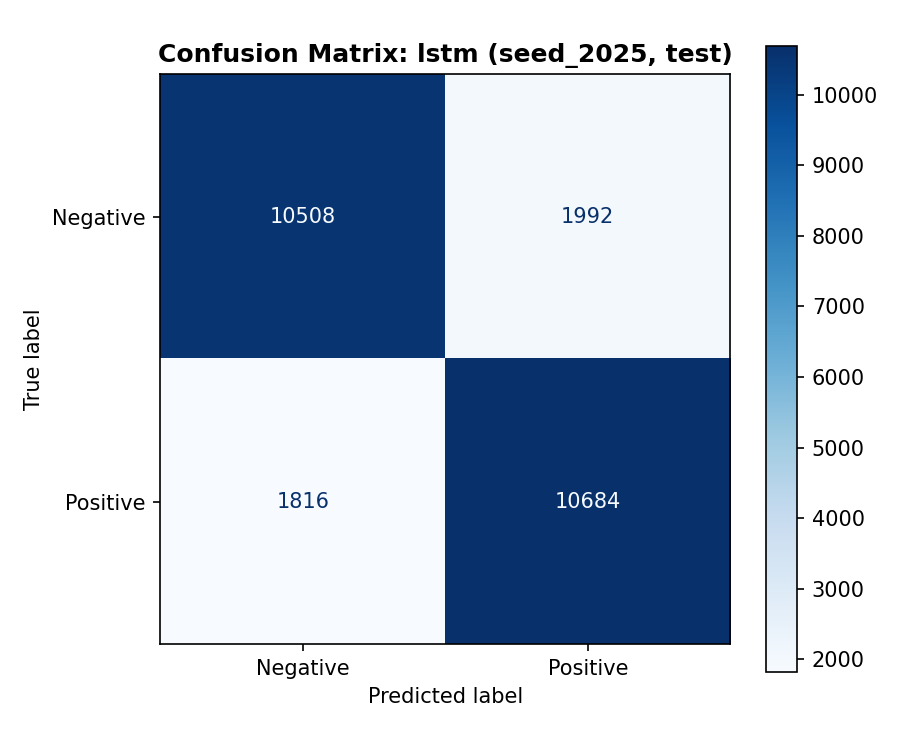

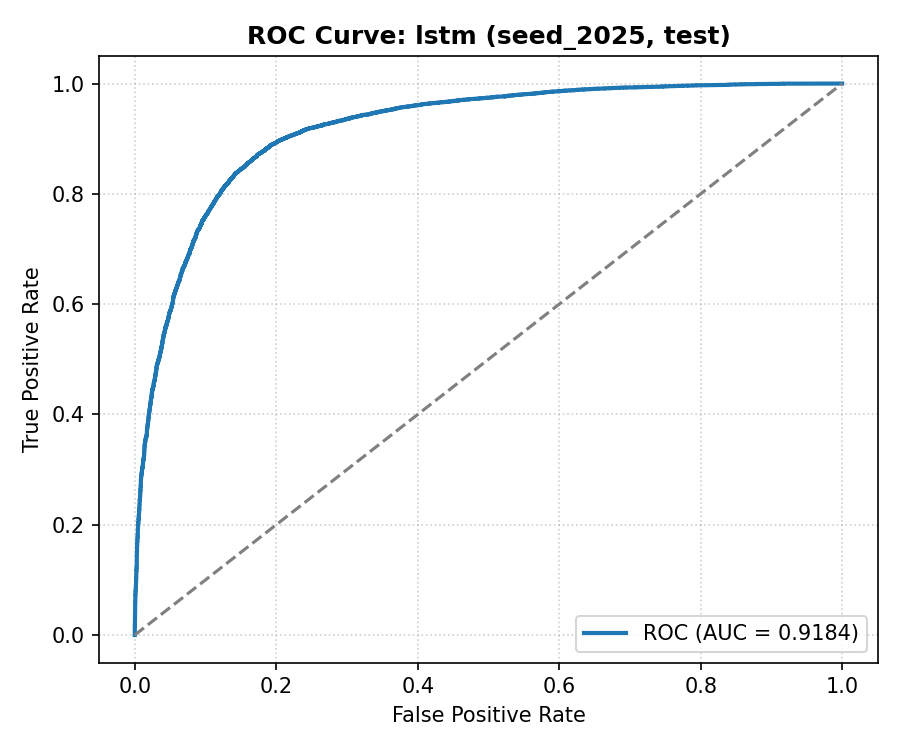

--- Đồ thị Đánh giá: gru (seed_123) ---


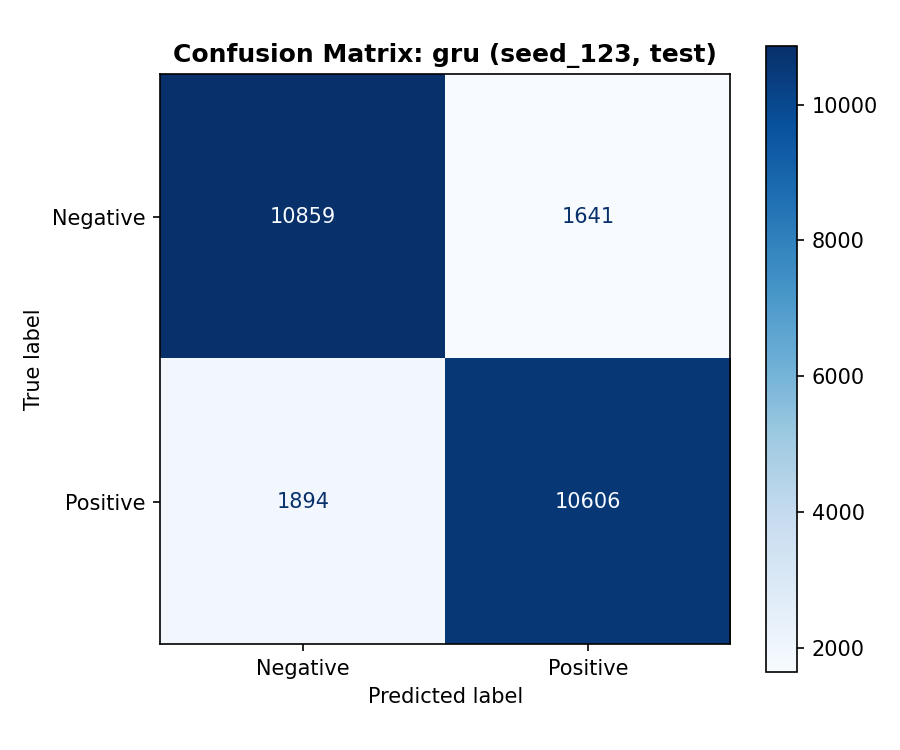

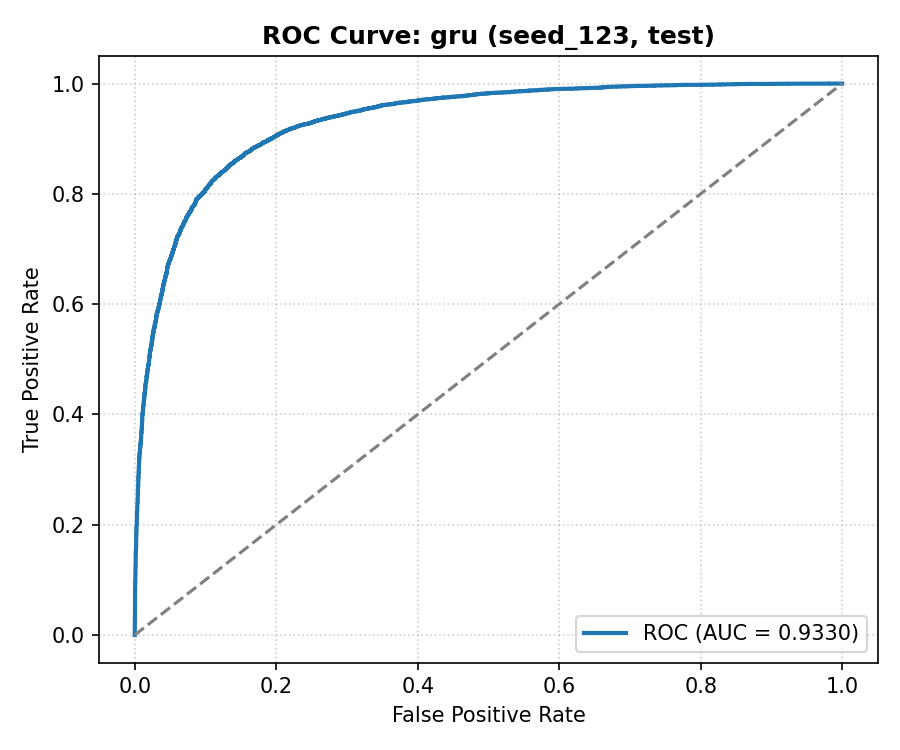

--- Đồ thị Đánh giá: bilstm (seed_42) ---


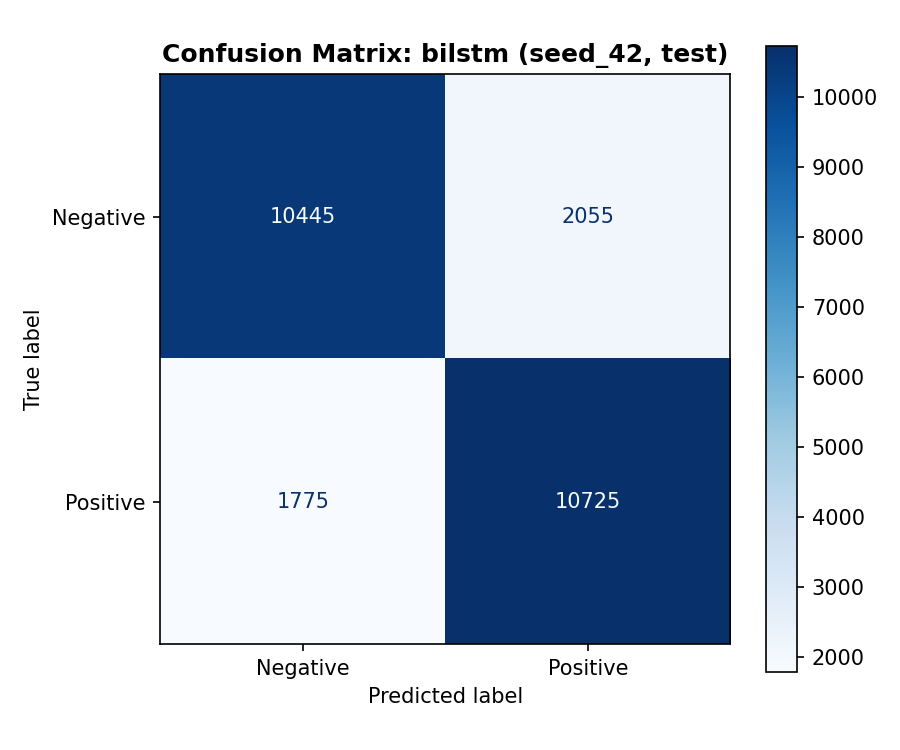

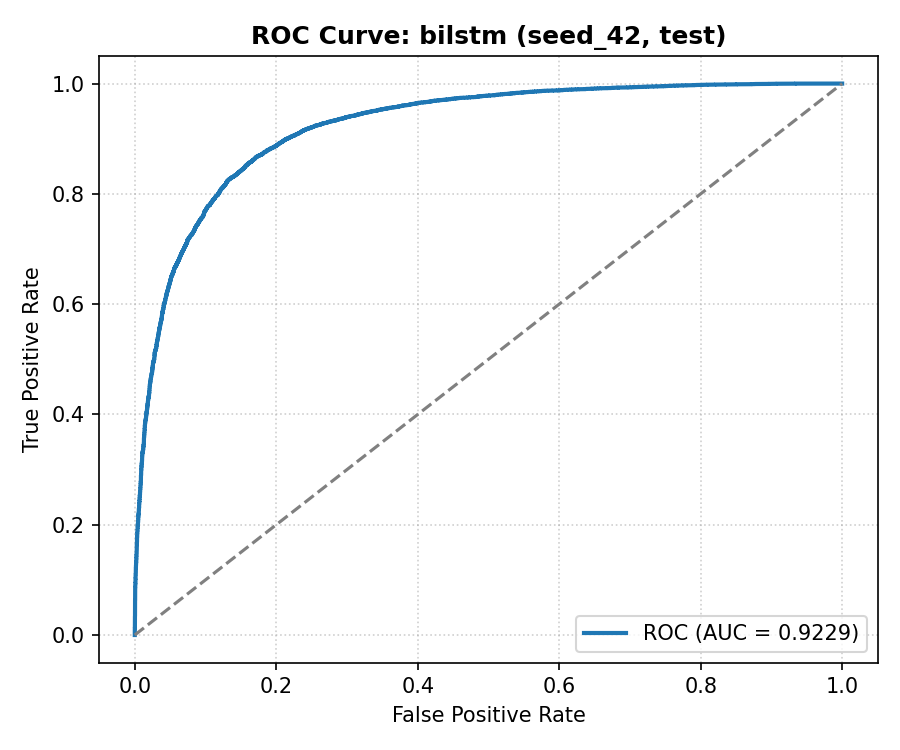

--- Đồ thị Đánh giá: bilstm_glove_frozen (seed_2025) ---


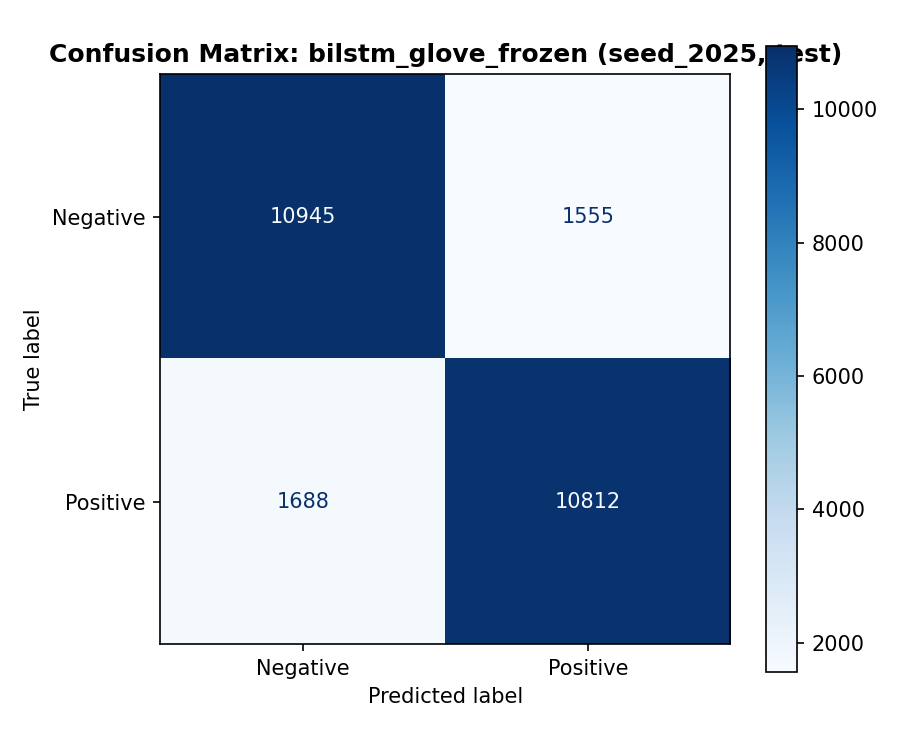

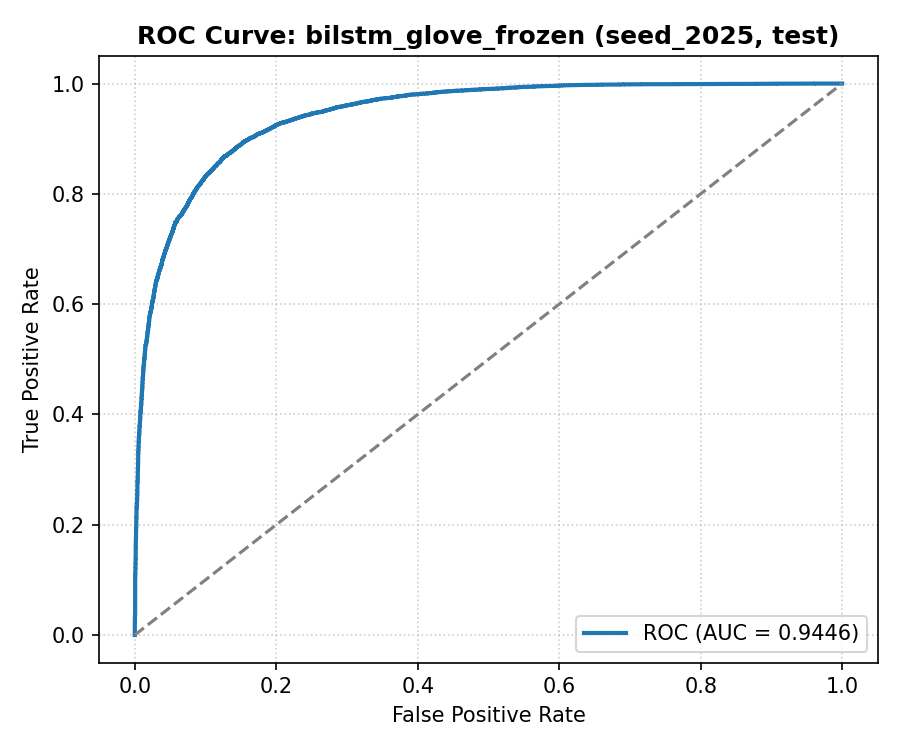

--- Đồ thị Đánh giá: bilstm_glove_ft (seed_42) ---


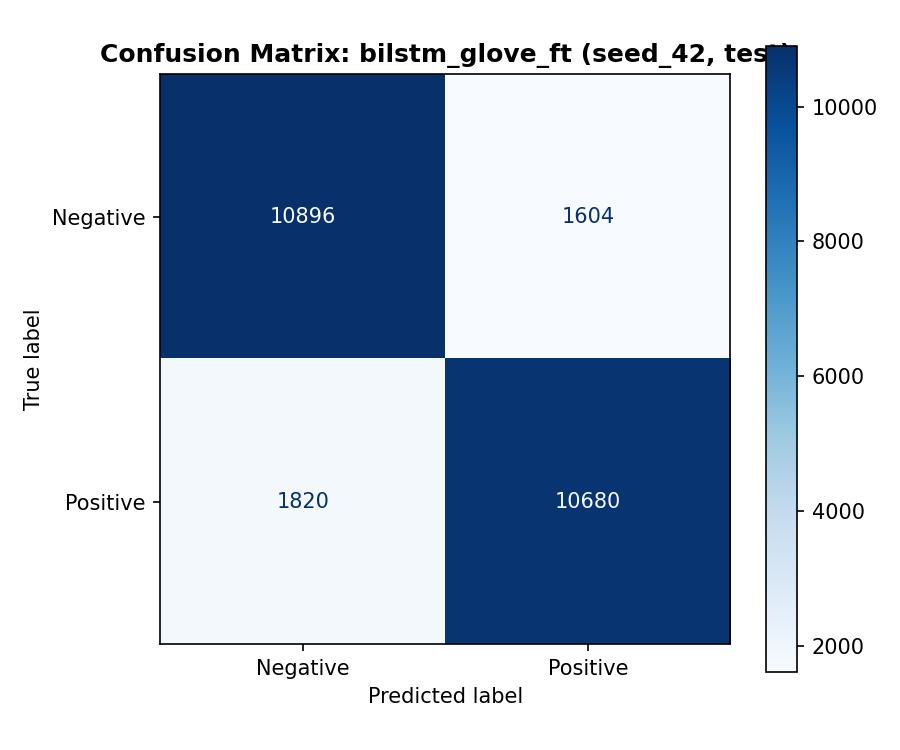

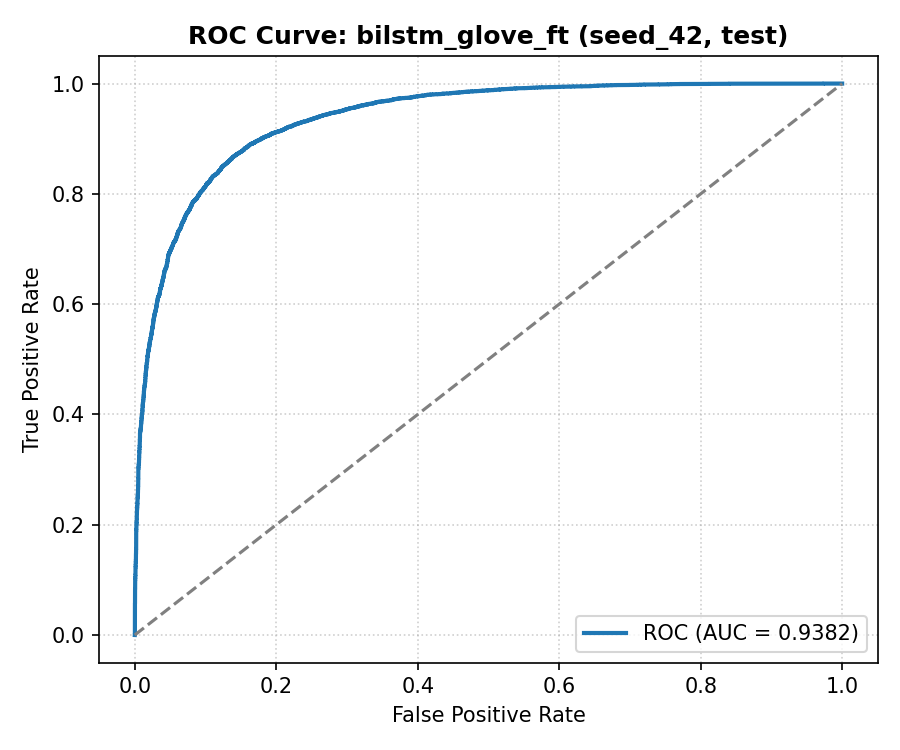

--- Đồ thị Đánh giá: bilstm_attention (seed_42) ---


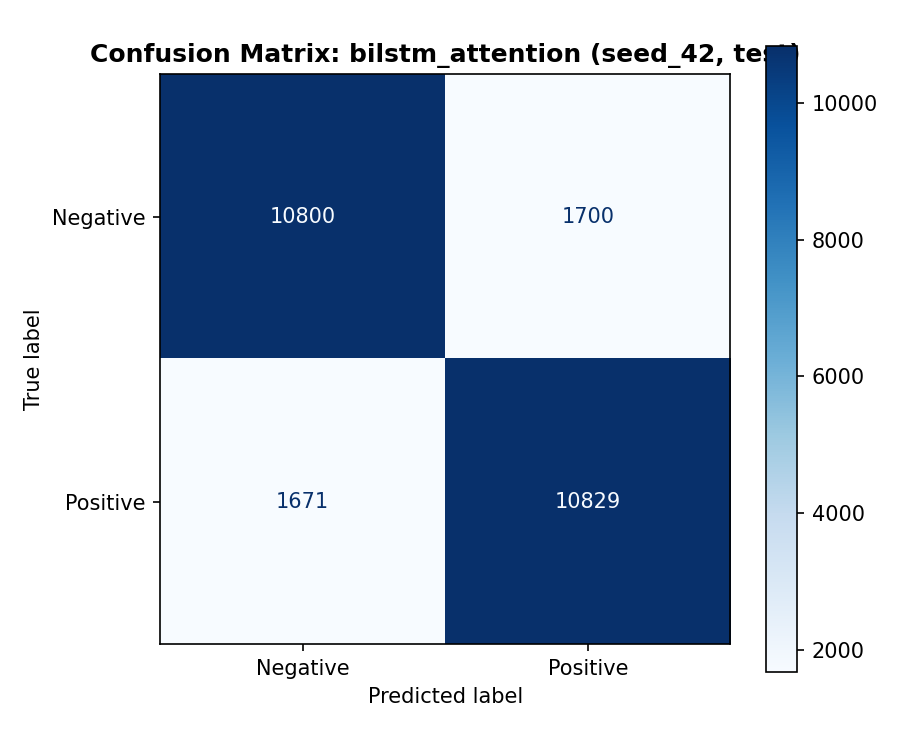

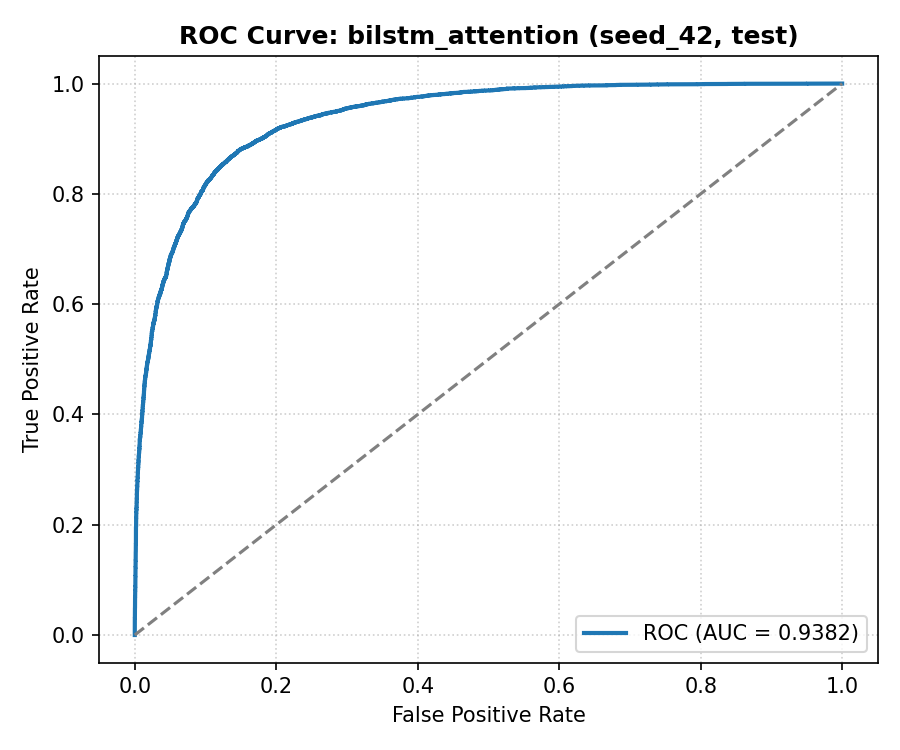

In [34]:
# Hiển thị đồ thị Confusion Matrix và ROC Curves trên tập Test (của seed tốt nhất theo Val cho mỗi mô hình)
eval_plots_dir = PROJECT_ROOT / "experiments" / "plots" / "eval"
for cfg_rel in CONFIG_LIST:
    exp_name = Path(cfg_rel).stem
    seed_to_show = BEST_SEED_BY_EXP.get(exp_name, 42)
    cm_path = eval_plots_dir / f"{exp_name}_seed_{seed_to_show}_test_cm.png"
    roc_path = eval_plots_dir / f"{exp_name}_seed_{seed_to_show}_test_roc.png"

    if cm_path.exists():
        print(f"--- Đồ thị Đánh giá: {exp_name} (seed_{seed_to_show}) ---")
        display(Image(filename=str(cm_path)))
    if roc_path.exists():
        display(Image(filename=str(roc_path)))


In [35]:
# Kiểm định Thống kê McNemar: Mô hình RNN Tốt Nhất (chọn theo Val) vs Baseline B1 (TF-IDF + LR)
b1_pred_file = PROJECT_ROOT / "experiments" / "results" / "baseline" / "predictions_test.csv"
best_model_name = f"{BEST_RNN_EXP}_seed{BEST_RNN_SEED}"
best_model_pred_file = PROJECT_ROOT / "experiments" / "results" / BEST_RNN_EXP / f"seed_{BEST_RNN_SEED}" / "predictions_test.csv"

if best_model_pred_file.exists() and b1_pred_file.exists():
    print(f"🔬 Thực hiện kiểm định McNemar: {best_model_name} vs Baseline B1 (TF-IDF + LR)...")
    mcnemar_res = run_mcnemar_cli(
        pred_file_a=best_model_pred_file,
        pred_file_b=b1_pred_file,
        model_a_name=best_model_name,
        model_b_name="Baseline_B1_TFIDF_LR",
        output_path=PROJECT_ROOT / "experiments" / "results" / "mcnemar.json",
    )

    print("\n📊 KẾT QUẢ KIỂM ĐỊNH MCNEMAR:")
    print(f"   - Chi-squared statistic: {mcnemar_res['statistic']:.4f}")
    print(f"   - P-value              : {mcnemar_res['p_value']:.4e}")
    print(f"   - Kết luận             : {'Sự khác biệt CÓ Ý NGHĨA THỐNG KÊ (p < 0.05)' if mcnemar_res['p_value'] < 0.05 else 'KHÔNG ĐỦ Ý NGHĨA THỐNG KÊ (p >= 0.05)'}")
    print("   - Bảng Contingency Table:")
    for k, v in mcnemar_res["contingency_table"].items():
        print(f"     * {k}: {v}")
else:
    print(f"⚠️ Thiếu file dự đoán test để chạy McNemar: {best_model_pred_file} hoặc {b1_pred_file}")


🔬 Thực hiện kiểm định McNemar: bilstm_attention_seed42 vs Baseline B1 (TF-IDF + LR)...


2026-11-24 14:10:43,225 [INFO] Đã lưu kết quả kiểm định McNemar vào /content/LSTM_PJ/experiments/results/mcnemar.json



📊 KẾT QUẢ KIỂM ĐỊNH MCNEMAR:
   - Chi-squared statistic: 265.2084
   - P-value              : 0.0000e+00
   - Kết luận             : Sự khác biệt CÓ Ý NGHĨA THỐNG KÊ (p < 0.05)
   - Bảng Contingency Table:
     * both_correct: 20584
     * a_correct_b_wrong: 1045
     * a_wrong_b_correct: 1935
     * both_wrong: 1436
     * total: 25000


## 9. Bàn giao Kết quả (Handover cho Thư & Bảo)

**Danh mục bàn giao theo `docs/TASKS.md` §4:**
1. **Bàn giao cho Bảo (Gradio Demo):** Checkpoint tốt nhất `best.pt` + `vocab.json` + hàm suy luận thời gian thực `predict_sentiment(text)`.
2. **Bàn giao cho Thư (Error Analysis & Báo cáo):** `predictions_test.csv` (đầy đủ 9 cột: `uid, text, label, rating, prob, pred, n_tokens, n_unk, was_truncated`), `comparison_test.csv`, `mcnemar.json`.


In [36]:
from src.predict import SentimentPredictor
import time
from pathlib import Path

# Dùng đúng mô hình & seed tốt nhất đã chốt theo Validation (nhất quán với Cell 27 McNemar)
best_exp = BEST_RNN_EXP
best_seed = BEST_RNN_SEED
ckpt_path = PROJECT_ROOT / "experiments" / "checkpoints" / best_exp / f"seed_{best_seed}" / "best.pt"
vocab_path = PROJECT_ROOT / "experiments" / "checkpoints" / best_exp / "vocab.json"

predictor = SentimentPredictor(checkpoint_path=ckpt_path, vocab_path=vocab_path)

test_cases = [
    "This was hands down one of the most brilliant and emotionally gripping movies I have ever seen.",
    "A total waste of two hours. Poor acting, predictable plot, and awful sound mixing.",
    "The acting was surprisingly decent, but the script was an absolute mess. Wouldn't recommend it.",
    "Not bad at all! Actually quite fun and entertaining for a Friday night movie.",
]

print(f"--- Thử nghiệm hàm dự đoán bàn giao cho Gradio Demo (Bảo) [{best_exp.upper()} | seed_{best_seed}] ---")
for text in test_cases:
    t0 = time.time()
    label, prob = predictor.predict(text)
    latency_ms = (time.time() - t0) * 1000
    sentiment = "Tích cực (Positive)" if label == 1 else "Tiêu cực (Negative)"
    print(f'Review: "{text}"')
    print(f" -> Dự đoán: {sentiment} (Xác suất: {prob*100:.2f}%) | Latency: {latency_ms:.2f}ms\n")


--- Thử nghiệm hàm dự đoán bàn giao cho Gradio Demo (Bảo) [BILSTM_ATTENTION | seed_42] ---
Review: "This was hands down one of the most brilliant and emotionally gripping movies I have ever seen."
 -> Dự đoán: Tích cực (Positive) (Xác suất: 97.07%) | Latency: 16.55ms

Review: "A total waste of two hours. Poor acting, predictable plot, and awful sound mixing."
 -> Dự đoán: Tiêu cực (Negative) (Xác suất: 0.00%) | Latency: 3.37ms

Review: "The acting was surprisingly decent, but the script was an absolute mess. Wouldn't recommend it."
 -> Dự đoán: Tiêu cực (Negative) (Xác suất: 0.07%) | Latency: 2.94ms

Review: "Not bad at all! Actually quite fun and entertaining for a Friday night movie."
 -> Dự đoán: Tích cực (Positive) (Xác suất: 99.17%) | Latency: 22.76ms



In [37]:
# KIỂM TRA ĐẦY ĐỦ CÁC ARTIFACTS BÀN GIAO THEO TASKS.MD §3-§4
handover_items = [
    ("reviews.parquet (B1)", PROJECT_ROOT / "data" / "processed" / "reviews.parquet"),
    ("vocab.json (D1)", PROJECT_ROOT / "data" / "processed" / "vocab.json"),
    ("glove_100d_vocab.npy (D3)", PROJECT_ROOT / "data" / "processed" / "glove_100d_vocab.npy"),
    ("baseline_tfidf_lr.joblib (B5)", PROJECT_ROOT / "experiments" / "checkpoints" / "baseline_tfidf_lr.joblib"),
    ("baseline predictions_test.csv (B5)", PROJECT_ROOT / "experiments" / "results" / "baseline" / "predictions_test.csv"),
    ("comparison_val.csv (D6)", PROJECT_ROOT / "experiments" / "results" / "comparison_val.csv"),
    ("maxlen_comparison.csv (D7)", PROJECT_ROOT / "experiments" / "results" / "maxlen_comparison.csv"),
    ("comparison_test.csv (D8)", PROJECT_ROOT / "experiments" / "results" / "comparison_test.csv"),
    ("mcnemar.json (D8)", PROJECT_ROOT / "experiments" / "results" / "mcnemar.json"),
    (f"Best RNN predictions_test.csv ({BEST_RNN_EXP})", PROJECT_ROOT / "experiments" / "results" / BEST_RNN_EXP / "predictions_test.csv"),
    (f"Best RNN checkpoint ({BEST_RNN_EXP}/seed_{BEST_RNN_SEED})", PROJECT_ROOT / "experiments" / "checkpoints" / BEST_RNN_EXP / f"seed_{BEST_RNN_SEED}" / "best.pt"),
    (f"Best RNN vocab.json ({BEST_RNN_EXP})", PROJECT_ROOT / "experiments" / "checkpoints" / BEST_RNN_EXP / "vocab.json"),
]

status_list = []
for name, p in handover_items:
    status_list.append({
        "Artifact": name,
        "Đường dẫn": str(p.relative_to(PROJECT_ROOT) if p.is_relative_to(PROJECT_ROOT) else p),
        "Trạng thái": "✅ ĐÃ CÓ" if p.exists() else "❌ CHƯA CÓ",
    })

print("📋 TRẠNG THÁI CÁC TÀI NGUYÊN BÀN GIAO:")
display(pd.DataFrame(status_list))


📋 TRẠNG THÁI CÁC TÀI NGUYÊN BÀN GIAO:


,Artifact,Đường dẫn,Trạng thái
0,reviews.parquet (B1),data/processed/reviews.parquet,✅ ĐÃ CÓ
1,vocab.json (D1),data/processed/vocab.json,✅ ĐÃ CÓ
2,glove_100d_vocab.npy (D3),data/processed/glove_100d_vocab.npy,✅ ĐÃ CÓ
3,baseline_tfidf_lr.joblib (B5),experiments/checkpoints/baseline_tfidf_lr.joblib,✅ ĐÃ CÓ
4,baseline predictions_test.csv (B5),experiments/results/baseline/predictions_test.csv,✅ ĐÃ CÓ
5,comparison_val.csv (D6),experiments/results/comparison_val.csv,✅ ĐÃ CÓ
6,maxlen_comparison.csv (D7),experiments/results/maxlen_comparison.csv,✅ ĐÃ CÓ
7,comparison_test.csv (D8),experiments/results/comparison_test.csv,✅ ĐÃ CÓ
8,mcnemar.json (D8),experiments/results/mcnemar.json,✅ ĐÃ CÓ
9,Best RNN predictions_test.csv (bilstm_attention),experiments/results/bilstm_attention/predictio...,✅ ĐÃ CÓ


In [38]:
import shutil
from pathlib import Path

zip_name = "LSTM_PJ_experiments_backup2"
folder_to_zip = PROJECT_ROOT / "experiments"
output_zip_path = Path(f"/content/{zip_name}") if Path("/content").exists() else PROJECT_ROOT / zip_name

if folder_to_zip.exists():
    print(f"📦 Đang nén thư mục '{folder_to_zip}' thành file ZIP...")
    shutil.make_archive(str(output_zip_path), "zip", root_dir=str(folder_to_zip))
    zip_file = Path(f"{output_zip_path}.zip")
    if zip_file.exists():
        print(f"✅ Đã tạo file ZIP thành công tại: {zip_file} ({zip_file.stat().st_size / (1024*1024):.2f} MB)")
        try:
            from google.colab import files
            print("📥 Đang kích hoạt tải file về máy tính cá nhân (Colab)...")
            files.download(str(zip_file))
        except ImportError:
            print("ℹ️ Không chạy trên Google Colab — bỏ qua bước tải tự động qua trình duyệt.")
else:
    print(f"⚠️ Không tìm thấy thư mục: {folder_to_zip} để thực hiện sao lưu.")


📦 Đang nén thư mục '/content/LSTM_PJ/experiments' thành file ZIP...
✅ Đã tạo file ZIP thành công tại: /content/LSTM_PJ_experiments_backup2.zip (542.65 MB)
📥 Đang kích hoạt tải file về máy tính cá nhân (Colab)...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
import shutil
from pathlib import Path

try:
    from google.colab import drive
    print("🔗 Đang kết nối với Google Drive của bạn...")
    drive.mount("/content/drive")
    source_file = Path("/content/LSTM_PJ_experiments_backup2.zip")
    destination_dir = Path("/content/drive/My Drive")
    if source_file.exists() and destination_dir.exists():
        destination_file = destination_dir / source_file.name
        print("📤 Đang sao chép file ZIP sang Google Drive...")
        shutil.copy(str(source_file), str(destination_file))
        print(f"✅ ĐÃ SAO LƯU THÀNH CÔNG LÊN GOOGLE DRIVE: My Drive/{source_file.name}")
except ImportError:
    print("ℹ️ Không chạy trên Google Colab — bỏ qua bước sao lưu Google Drive.")


🔗 Đang kết nối với Google Drive của bạn...
Mounted at /content/drive
📤 Đang sao chép file ZIP sang Google Drive...
✅ ĐÃ SAO LƯU THÀNH CÔNG LÊN GOOGLE DRIVE: My Drive/LSTM_PJ_experiments_backup2.zip
